# Ưu tiên phản hồi bài đăng sinh viên bằng học máy

Notebook tái tạo dữ liệu, baseline TF-IDF, MiniLM frozen và MiniLM fine-tuned. Có đủ Precision, Recall, F1, Macro-F1, AP, ROC-AUC, P@20/R@20, ma trận nhầm lẫn và phân tích lỗi.

**Kaggle:** bật Internet và chọn GPU trong Settings trước Run All. Không cần Google Drive, tài khoản Hugging Face hoặc API key. MiniLM được tải ở revision cố định. Chạy đủ hai nguồn và 5-fold sẽ lâu hơn bản chỉ trích embeddings.

GPU T4 ×2 dùng được. Trainer hiện dùng một GPU cho mỗi lượt chạy, chưa phân tán trên cả hai GPU. Trên T4, fine-tuning dùng FP32; BF16 chỉ bật khi CUDA hỗ trợ phần cứng trực tiếp.

Test đã được xem trong các thí nghiệm trước, vì vậy các so sánh mở rộng được ghi nhận là **exploratory**. Không chọn epoch, cấu hình hoặc ngưỡng bằng test. Nhãn là `int(urgency > 4)`; phạm vi tiếng Anh.


In [1]:
import os, sys, json, subprocess, importlib.util
from pathlib import Path
from IPython.display import display, Markdown, HTML, Image

IS_KAGGLE = Path('/kaggle/working').exists()
PROJECT = Path(os.environ.get('FORUM_PROJECT_DIR', '/kaggle/working/Project' if IS_KAGGLE else str(Path.cwd() / 'Project'))).resolve()
PROJECT.mkdir(parents=True, exist_ok=True)
for folder in ['scripts','data/raw','data/processed','models','reports/experiments','reports/fine_tuning','reports/figures','.cache/tmp']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT), HF_HOME=str(PROJECT/'.cache/huggingface'),
    HF_HUB_CACHE=str(PROJECT/'.cache/huggingface/hub'), HF_XET_CACHE=str(PROJECT/'.cache/huggingface/xet'),
    TORCH_HOME=str(PROJECT/'.cache/torch'), MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),
    TMPDIR=str(PROJECT/'.cache/tmp'), PIP_CACHE_DIR=str(PROJECT/'.cache/pip'),
    TOKENIZERS_PARALLELISM='false', HF_HUB_DISABLE_TELEMETRY='1', PYTORCH_ENABLE_MPS_FALLBACK='1',
    OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')

# Default: train from the pinned data. Local QA may explicitly reuse completed artifacts.
RUN_TRAINING = os.environ.get('FORUM_REUSE_EXISTING', '0') != '1'
MAX_EPOCHS = 3
PATIENCE = 1
FOLDS = 5
BATCH_SIZE = 64
MAX_LENGTH = 256
print('Project:', PROJECT)
print('Execution mode:', 'TRAIN MODELS' if RUN_TRAINING else 'REUSE COMPLETED TRAINING ARTIFACTS (explicit local QA mode)')


Project: /Users/nhaterik/lastyear/machine/Project
Execution mode: REUSE COMPLETED TRAINING ARTIFACTS (explicit local QA mode)


## Thư viện và thiết bị

Không tải hoặc cài lại PyTorch nếu môi trường đã có. Khi thiếu thư viện, cell dưới cài vào môi trường notebook. Trên Mac, dùng môi trường `.venv` của Project; trên Kaggle, dùng môi trường notebook của Kaggle. Các phiên bản thực tế được in và ghi lại.


In [2]:
required = {'transformers':'transformers==4.57.6', 'sentence_transformers':'sentence-transformers>=5,<6',
            'sklearn':'scikit-learn>=1.7,<2', 'matplotlib':'matplotlib>=3.10,<4', 'torch':'torch>=2.8'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
import torch, transformers, sklearn, numpy as np
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
USE_BF16 = (DEVICE == 'mps') or (DEVICE == 'cuda' and torch.cuda.is_bf16_supported(including_emulation=False))
if IS_KAGGLE and RUN_TRAINING and DEVICE != 'cuda':
    raise RuntimeError('Enable GPU in Kaggle Settings, then Run All again.')
versions = {'python':sys.version, 'torch':torch.__version__, 'transformers':transformers.__version__,
            'sklearn':sklearn.__version__, 'numpy':np.__version__, 'device':DEVICE, 'bf16':USE_BF16,
            'cuda_devices_visible':torch.cuda.device_count() if DEVICE == 'cuda' else 0,
            'cuda_device_used':torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
            'training_gpu_count':1 if DEVICE == 'cuda' else 0}
print(json.dumps(versions, indent=2))
(PROJECT/'reports/notebook_environment.json').write_text(json.dumps(versions, indent=2))


/Users/nhaterik/lastyear/machine/Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]",
  "torch": "2.15.0",
  "transformers": "4.57.6",
  "sklearn": "1.9.1",
  "numpy": "2.5.4",
  "device": "mps",
  "bf16": true,
  "cuda_devices_visible": 0,
  "cuda_device_used": null,
  "training_gpu_count": 0
}


303

## Mã nguồn được đóng gói trong notebook

Các cell dưới ghi từng script đầy đủ, không phụ thuộc repository cá nhân. Mã được hiển thị theo dòng để giảng viên đọc thuật toán và quy trình. SHA-256 được in để kiểm tra phiên bản mã.


In [3]:
SOURCES = {}


### Script prepare_data.py


In [4]:
SOURCES['prepare_data.py'] = r'''"""Download and audit two pinned public datasets using only Python's standard library."""
from __future__ import annotations

import argparse
import csv
import hashlib
import html
import json
import math
import re
import subprocess
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
REVISION = "ebf3695f01d2dec197253eb89499f4835bb7d0fa"
FILES = {"upenn": "All_Courses_REDACTED_CODED.csv", "stanford": "Stanford.csv"}
EXPECTED_SHA256 = {
    "upenn": "403301d079abcea1acc318b7a63f766658350dbc0e85eead79f7befc65aa48c3",
    "stanford": "31e8885939604a20cd0a903d1e5ebca811b850530b8e9ed5169e1936628142f2",
}
FIELDS = ["post_id", "source", "source_row", "source_id", "source_time", "source_course_type", "text_raw",
          "text_clean", "urgency", "priority", "word_count", "text_sha256"]
TAG = re.compile(r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>", re.I)


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def dump_json(path: Path, data) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")


def clean_text(text: str) -> str:
    return " ".join(TAG.sub(" ", unicodedata.normalize("NFC", html.unescape(text))).split())


def percentile(values, fraction):
    ordered = sorted(values)
    index = (len(ordered) - 1) * fraction
    low = math.floor(index)
    high = math.ceil(index)
    return round(ordered[low] + (ordered[high] - ordered[low]) * (index - low), 2)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--download", action="store_true", help="Download missing raw files, never replace existing files")
    args = parser.parse_args()
    rejected, datasets, audit = [], {}, {"source_revision": REVISION, "label_rule": "priority = int(urgency > 4)", "datasets": {}}
    for source, filename in FILES.items():
        path = ROOT / "data/raw" / filename
        url = f"https://raw.githubusercontent.com/pcla-code/forum-posts-urgency/{REVISION}/{filename}"
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            if not args.download:
                raise SystemExit(f"Thiếu {path.name}. Chạy bash Project/run.sh --download từ machine.")
            print(f"Đang tải {source} từ commit {REVISION[:12]}...", flush=True)
            temporary = path.with_suffix(".csv.part")
            try:
                subprocess.run(["curl", "-q", "--fail", "--location", "--silent", "--show-error",
                                "--connect-timeout", "10", "--max-time", "120", "--retry", "1",
                                "--output", str(temporary), url], check=True)
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        if sha256(path) != EXPECTED_SHA256[source]:
            raise ValueError(f"SHA-256 tệp gốc không khớp phiên bản cố định: {filename}")
        groups = defaultdict(list)
        counts = Counter()
        with path.open(encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not {"post_text", "Urgency_1_7"}.issubset(reader.fieldnames or []):
                raise ValueError(f"Schema không phù hợp: {path.name}")
            columns = reader.fieldnames
            for row_number, raw in enumerate(reader, start=2):
                counts["raw_rows"] += 1
                reason = None
                if None in raw or raw.get("post_text") is None or raw.get("Urgency_1_7") is None:
                    reason = "malformed_or_missing_fields"
                try:
                    urgency = float(raw.get("Urgency_1_7") or "nan")
                except (TypeError, ValueError):
                    urgency = float("nan")
                if reason is None and (not math.isfinite(urgency) or not 1 <= urgency <= 7):
                    reason = "missing_or_invalid_urgency"
                text = clean_text(raw.get("post_text") or "")
                if reason is None and not text:
                    reason = "empty_text"
                if reason:
                    counts[reason] += 1
                    rejected.append({"source": source, "source_row": row_number, "reason": reason})
                    continue
                counts["valid_rows"] += 1
                key = hashlib.sha256(text.casefold().encode("utf-8")).hexdigest()
                groups[key].append({"post_id": f"{source}_{row_number:06d}", "source": source,
                                    "source_row": row_number, "source_id": raw.get("id", ""),
                                    "source_time": raw.get("post_time", ""),
                                    "source_course_type": raw.get("CourseType", ""), "text_raw": raw["post_text"],
                                    "text_clean": text, "urgency": urgency, "priority": int(urgency > 4),
                                    "word_count": len(text.split()), "text_sha256": key})
        retained = []
        for rows in groups.values():
            conflict = len({row["priority"] for row in rows}) > 1
            if conflict:
                counts["conflicting_groups"] += 1
            discarded = rows if conflict else rows[1:]
            reason = "conflicting_binary_labels" if conflict else "duplicate_within_source"
            counts[reason] += len(discarded)
            rejected.extend({"source": source, "source_row": row["source_row"], "reason": reason} for row in discarded)
            if not conflict:
                retained.append(rows[0])
        counts["after_within_source_dedup"] = len(retained)
        counts["cross_source_duplicates"] = 0
        datasets[source] = sorted(retained, key=lambda row: row["source_row"])
        audit["datasets"][source] = {"raw_file": str(path.relative_to(ROOT)), "url": url,
                                       "raw_sha256": sha256(path), "raw_bytes": path.stat().st_size,
                                       "columns": columns, "counts": dict(counts)}

    upenn_keys = {row["text_sha256"] for row in datasets["upenn"]}
    unique_stanford = []
    for row in datasets["stanford"]:
        if row["text_sha256"] in upenn_keys:
            audit["datasets"]["stanford"]["counts"]["cross_source_duplicates"] += 1
            rejected.append({"source": "stanford", "source_row": row["source_row"], "reason": "duplicate_across_sources"})
        else:
            unique_stanford.append(row)
    datasets["stanford"] = unique_stanford

    for source, rows in datasets.items():
        if not rows:
            raise ValueError(f"Không có dữ liệu hợp lệ: {source}")
        target = ROOT / "data/processed" / f"{source}.csv"
        target.parent.mkdir(parents=True, exist_ok=True)
        with target.open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(rows)
        item = audit["datasets"][source]
        item["counts"]["final_rows"] = len(rows)
        item["label_counts"] = dict(Counter(str(row["priority"]) for row in rows))
        item["urgency_counts"] = dict(Counter(str(row["urgency"]) for row in rows))
        lengths = [row["word_count"] for row in rows]
        item["word_lengths"] = {"min": min(lengths), "median": percentile(lengths, .5),
                                 "p95": percentile(lengths, .95), "max": max(lengths),
                                 "mean": round(sum(lengths) / len(lengths), 2)}
        bounds = [(0, 25), (25, 50), (50, 100), (100, 200), (200, 400), (400, None)]
        item["length_histogram"] = {f"{lower + 1}–{upper}" if upper else f">{lower}":
            sum(length > lower and (upper is None or length <= upper) for length in lengths)
            for lower, upper in bounds}
        item["processed_file"] = str(target.relative_to(ROOT))
        item["processed_sha256"] = sha256(target)
        n_rejected = sum(record["source"] == source for record in rejected)
        assert item["counts"]["raw_rows"] == len(rows) + n_rejected
        assert all(row["text_clean"].strip() for row in rows)
        assert all(math.isfinite(row["urgency"]) and 1 <= row["urgency"] <= 7 for row in rows)
        assert all(row["priority"] == int(row["urgency"] > 4) for row in rows)
        assert len({row["text_sha256"] for row in rows}) == len(rows)
        assert {row["priority"] for row in rows} == {0, 1}
        print(f"{source}: raw={item['counts']['raw_rows']}, final={len(rows)}, priority={item['label_counts'].get('1', 0)}", flush=True)
    assert not ({row["text_sha256"] for row in datasets["upenn"]} &
                {row["text_sha256"] for row in datasets["stanford"]})
    audit["checks"] = {"rows_accounted_for": True, "nonempty_text": True, "labels_in_range": True,
                        "both_binary_classes_present": True, "no_exact_duplicates_within_sources": True,
                        "no_exact_duplicates_between_sources": True}
    dump_json(ROOT / "reports/data_audit.json", audit)
    with (ROOT / "reports/rejected_rows.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["source", "source_row", "reason"])
        writer.writeheader()
        writer.writerows(sorted(rejected, key=lambda row: (row["source"], row["source_row"])))


if __name__ == "__main__":
    main()
'''
(PROJECT/"scripts"/'prepare_data.py').write_text(SOURCES['prepare_data.py'], encoding="utf-8")


9552

### Script train.py


In [5]:
SOURCES['train.py'] = r'''"""Reproducible source-only model selection and two-source held-out evaluation."""
from __future__ import annotations
import csv
import hashlib
import json
import platform
import sys
import time
from pathlib import Path
import joblib
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold,
    train_test_split, GridSearchCV, cross_val_predict)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from prepare_data import dump_json, sha256

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/experiments'
SEED=42
ENCODER='sentence-transformers/all-MiniLM-L6-v2'
ENCODER_REV='1110a243fdf4706b3f48f1d95db1a4f5529b4d41'

def read_csv(path):
    with path.open(encoding='utf-8',newline='') as f:
        return list(csv.DictReader(f))

def write_csv(path, rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    with path.open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader();writer.writerows(rows)

def scores(model,x):
    if hasattr(model,'predict_proba'):
        return model.predict_proba(x)[:,1]
    return model.decision_function(x)

def metrics(y,s,t,ids):
    p=np.asarray(s)>=t
    matrix=confusion_matrix(y,p,labels=[0,1])
    order=np.lexsort((np.asarray(ids),-np.asarray(s)))
    k=min(20,len(y));found=int(np.asarray(y)[order[:k]].sum())
    return dict(precision=float(precision_score(y,p,zero_division=0)),recall=float(recall_score(y,p,zero_division=0)),
        f1=float(f1_score(y,p,zero_division=0)),macro_f1=float(f1_score(y,p,average='macro')),
        accuracy=float(accuracy_score(y,p)),average_precision=float(average_precision_score(y,s)),
        roc_auc=float(roc_auc_score(y,s)),precision_at_20=found/k,recall_at_20=found/int(np.sum(y)),
        top20_found=found,confusion_matrix=matrix.tolist(),test_size=len(y),positive_count=int(np.sum(y)))

def tune_threshold(y,s):
    precision,recall,thresholds=precision_recall_curve(y,s)
    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    # Highest threshold among exact F1 ties; no target test labels are used.
    index=np.flatnonzero(np.isclose(f,np.max(f),atol=1e-12,rtol=0))[-1]
    return float(thresholds[index]),float(f[index])

def embeddings(data):
    import torch
    from sentence_transformers import SentenceTransformer
    from huggingface_hub import snapshot_download
    snapshot=snapshot_download(ENCODER,revision=ENCODER_REV,
        allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    torch.manual_seed(SEED)
    encoder=SentenceTransformer(snapshot,device=device)
    result={};info={'model':ENCODER,'revision':ENCODER_REV,'device':device,
        'snapshot':str(Path(snapshot).relative_to(ROOT)),'max_seq_length':encoder.max_seq_length,
        'dimension':(encoder.get_embedding_dimension() if hasattr(encoder,'get_embedding_dimension')
                     else encoder.get_sentence_embedding_dimension()),'sources':{}}
    for source,rows in data.items():
        path=ROOT/'.cache/embeddings'/f'{source}.npz';path.parent.mkdir(parents=True,exist_ok=True)
        fingerprint=sha256(ROOT/f'data/processed/{source}.csv')
        if path.exists():
            cached=np.load(path)
            if str(cached['fingerprint'])==fingerprint and str(cached['revision'])==ENCODER_REV:
                result[source]=cached['vectors'];info['sources'][source]={'cache_used':True};continue
        texts=[row['text_clean'] for row in rows]
        start=time.perf_counter()
        lengths=[]
        for i in range(0,len(texts),128):
            batch=encoder.tokenizer(texts[i:i+128],truncation=False,add_special_tokens=True)['input_ids']
            lengths.extend(map(len,batch))
        vectors=encoder.encode(texts,batch_size=64,normalize_embeddings=True,show_progress_bar=True).astype(np.float32)
        elapsed=time.perf_counter()-start
        np.savez_compressed(path,vectors=vectors,fingerprint=fingerprint,revision=ENCODER_REV)
        result[source]=vectors
        info['sources'][source]={'cache_used':False,'encoding_seconds':elapsed,
            'truncated_posts':sum(n>encoder.max_seq_length for n in lengths),'total':len(texts),
            'tokens_p95':float(np.percentile(lengths,95)),'tokens_max':max(lengths)}
        dump_json(OUT/'encoder_info.json',info)
    # Preserve original measured token/encoding stats when embeddings are reused.
    if (OUT/'encoder_info.json').exists():
        previous=json.loads((OUT/'encoder_info.json').read_text())
        for source,entry in info['sources'].items():
            if entry.get('cache_used') and source in previous.get('sources',{}):
                info['sources'][source]=previous['sources'][source]
    dump_json(OUT/'encoder_info.json',info)
    return result,info

def main():
    OUT.mkdir(parents=True,exist_ok=True)
    (ROOT/'models').mkdir(exist_ok=True)
    data={source:read_csv(ROOT/f'data/processed/{source}.csv') for source in ['upenn','stanford']}
    splits={};folds={};split_rows=[];split_info={}
    for source,rows in data.items():
        y=np.array([int(row['priority']) for row in rows]);indices=np.arange(len(rows))
        if source=='upenn':
            groups=np.array([row['source_id'] for row in rows])
            assert all(groups)
            train,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(indices,y,groups))
            folds[source]=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train],groups[train]))
            assert not (set(groups[train]) & set(groups[test]))
            policy='GroupShuffleSplit by UPenn student id; 3-fold StratifiedGroupKFold for tuning'
        else:
            train,test=train_test_split(indices,test_size=.2,random_state=SEED,stratify=y)
            folds[source]=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train]))
            policy='Stratified hold-out and 3-fold StratifiedKFold; author/thread IDs unavailable'
        for a,b in folds[source]:
            assert len(set(y[train[a]]))==2 and len(set(y[train[b]]))==2
        splits[source]=(train,test)
        split_info[source]={'policy':policy,'train':len(train),'test':len(test),
            'train_positives':int(y[train].sum()),'test_positives':int(y[test].sum()),
            'processed_sha256':sha256(ROOT/f'data/processed/{source}.csv')}
        train_set=set(train)
        assignments={int(i):('train' if i in train_set else 'test') for i in indices}
        split_rows.extend({'source':source,'post_id':row['post_id'],'split':assignments[i]} for i,row in enumerate(rows))
    write_csv(OUT/'split_ids.csv',split_rows);dump_json(OUT/'split_info.json',split_info)
    dump_json(OUT/'config.json',{'seed':SEED,'folds':3,'test_fraction':.2,'tfidf':{
        'ngram_range':[1,2],'min_df':2,'max_df':.98,'max_features':40000,'sublinear_tf':True},
        'threshold_rule':'Maximize positive F1 on source-only out-of-fold predictions; ties use largest threshold',
        'deployment_rule':'Best tuned OOF F1 among Stanford-trained models; independent test scores not used',
        'encoder_revision':ENCODER_REV,'data_hashes':{s:i['processed_sha256'] for s,i in split_info.items()}})
    results=[];cv_records=[]
    # Train TF-IDF first, so useful artifacts exist before downloading the optional encoder.
    embedded=None;encoder_info=None
    for representation in ['tfidf','minilm']:
        if representation=='minilm':
            embedded,encoder_info=embeddings(data)
        for source,rows in data.items():
            train,_=splits[source]
            y=np.array([int(row['priority']) for row in rows]);texts=np.array([row['text_clean'] for row in rows],dtype=object)
            x=texts if representation=='tfidf' else embedded[source]
            if representation=='tfidf':
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('svm',LinearSVC(class_weight='balanced',max_iter=10000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('nb',MultinomialNB(),{'classifier__alpha':[.1,.5,1.]}),
                    ('dummy',DummyClassifier(strategy='prior'),{})]
            else:
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'C':[.3,1.,3.,10.]})]
            for name,classifier,grid in candidates:
                slug=f'{representation}_{name}'
                print(f'TRAIN {source} / {slug}',flush=True)
                if representation=='tfidf':
                    model=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=40000,
                        sublinear_tf=True,strip_accents='unicode',dtype=np.float32)),('classifier',classifier)])
                else:model=classifier
                start=time.perf_counter()
                search=GridSearchCV(model,grid,cv=folds[source],scoring='f1',n_jobs=1,refit=True,return_train_score=False)
                search.fit(x[train],y[train]);model=search.best_estimator_
                method='decision_function' if name=='svm' else 'predict_proba'
                oof=cross_val_predict(clone(model),x[train],y[train],cv=folds[source],method=method,n_jobs=1)
                oof=oof if name=='svm' else oof[:,1]
                default=0. if name=='svm' else .5
                threshold,oof_f1=tune_threshold(y[train],oof)
                if name=='dummy': threshold=default;oof_f1=float(f1_score(y[train],oof>=threshold,zero_division=0))
                elapsed=time.perf_counter()-start
                card={'source':source,'model':slug,'representation':representation,'name':name,
                    'threshold':threshold,'default_threshold':default,'cv_mean_f1':float(search.best_score_),
                    'cv_std_f1':float(search.cv_results_['std_test_score'][search.best_index_]),
                    'oof_tuned_f1':oof_f1,'best_params':search.best_params_,'training_seconds':elapsed}
                if representation=='minilm':card['encoder']=encoder_info
                cv_records.append(card)
                bundle={'model':model,'card':card}
                joblib.dump(bundle,ROOT/'models'/f'{source}__{slug}.joblib',compress=3)
                write_csv(OUT/f'oof_{source}_{slug}.csv',[{'post_id':rows[i]['post_id'],'label':int(y[i]),'score':float(s)} for i,s in zip(train,oof)])
                for target,target_rows in data.items():
                    _,test=splits[target]
                    test_x=np.array([row['text_clean'] for row in target_rows],dtype=object)[test] if representation=='tfidf' else embedded[target][test]
                    test_y=np.array([int(row['priority']) for row in target_rows])[test]
                    ids=[target_rows[i]['post_id'] for i in test]
                    start=time.perf_counter();s=scores(model,test_x);infer_seconds=time.perf_counter()-start
                    record={'train_source':source,'test_source':target,'model':slug,'threshold':threshold,
                        'training_seconds':elapsed,'inference_seconds':infer_seconds,**metrics(test_y,s,threshold,ids)}
                    record['default_threshold_metrics']=metrics(test_y,s,default,ids)
                    results.append(record)
                    prediction_rows=[]
                    for i,label,score in zip(test,test_y,s):
                        row=target_rows[i];pred=int(score>=threshold)
                        prediction_rows.append({'post_id':row['post_id'],'source':target,'source_id':row['source_id'],
                            'course_type':row['source_course_type'],'text':row['text_clean'],'urgency':row['urgency'],
                            'label':int(label),'predicted':pred,'score':float(score),
                            'error':'FN' if label==1 and pred==0 else 'FP' if label==0 and pred==1 else ''})
                    write_csv(OUT/f'predictions_{source}_{target}_{slug}.csv',prediction_rows)
                    print(f'  TEST {target}: P={record["precision"]:.3f} R={record["recall"]:.3f} F1={record["f1"]:.3f}',flush=True)
                dump_json(OUT/'results.json',results);dump_json(OUT/'cv_results.json',cv_records)
    selected=max((r for r in cv_records if r['source']=='stanford' and r['name']!='dummy'),key=lambda r:r['oof_tuned_f1'])
    dump_json(ROOT/'models/deployment.json',{'source':selected['source'],'model':selected['model'],
        'file':f"models/{selected['source']}__{selected['model']}.joblib",'selection_rule':'Stanford source training OOF F1 only',
        'oof_tuned_f1':selected['oof_tuned_f1'],'threshold':selected['threshold']})
    dump_json(OUT/'training_environment.json',{'python':sys.version,'sklearn':sklearn.__version__,
        'numpy':np.__version__,'platform':platform.platform(),'seed':SEED})
    print('DEPLOYMENT',selected['source'],selected['model'],flush=True)

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'train.py').write_text(SOURCES['train.py'], encoding="utf-8")


13597

### Script finetune_minilm.py


In [6]:
SOURCES['finetune_minilm.py'] = r'''"""Portable supervised MiniLM fine-tuning, source-only selection, CV and offline export."""
from __future__ import annotations
import argparse,csv,gc,hashlib,json,math,os,random,time,sys
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import torch
from sklearn.model_selection import GroupShuffleSplit,StratifiedGroupKFold,StratifiedKFold,train_test_split
from sklearn.metrics import average_precision_score,f1_score
from transformers import AutoTokenizer,AutoModelForSequenceClassification,get_linear_schedule_with_warmup
from train import metrics,tune_threshold,read_csv,write_csv,ENCODER,ENCODER_REV
from prepare_data import dump_json,sha256,clean_text

ROOT=Path(os.environ.get('PROJECT_ROOT',Path(__file__).resolve().parents[1])).resolve()
OUT=ROOT/'reports/fine_tuning'
CONFIGS={
    'plain':{'weighted':False,'augmentation':False,'lr':2e-5},
    'weighted':{'weighted':True,'augmentation':False,'lr':2e-5},
    'weighted_aug':{'weighted':True,'augmentation':True,'lr':2e-5},
}
MIXED_PRECISION=False

def autocast(device):
    return torch.autocast(device_type=device,dtype=torch.bfloat16) if MIXED_PRECISION else nullcontext()
CONTRACTIONS={"can't":"cannot","won't":"will not","don't":"do not","doesn't":"does not",
    "didn't":"did not","isn't":"is not","aren't":"are not","wasn't":"was not","weren't":"were not",
    "couldn't":"could not","wouldn't":"would not","shouldn't":"should not","haven't":"have not",
    "hasn't":"has not","hadn't":"had not","i'm":"I am","you're":"you are","we're":"we are",
    "they're":"they are","i've":"I have","we've":"we have","i'll":"I will","we'll":"we will"}

def augment(text):
    import re
    text=text.replace('’',"'")
    return re.sub(r"\b(?:"+'|'.join(re.escape(k) for k in CONTRACTIONS)+r")\b",
                  lambda m:CONTRACTIONS[m.group(0).lower()],text,flags=re.I)

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)

def snapshot():
    local=ROOT/'.cache/huggingface/hub'/('models--'+ENCODER.replace('/','--'))/'snapshots'/ENCODER_REV
    if local.exists():return str(local)
    from huggingface_hub import snapshot_download
    return snapshot_download(ENCODER,revision=ENCODER_REV,allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])

def setup():
    OUT.mkdir(parents=True,exist_ok=True)
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    tokenizer=AutoTokenizer.from_pretrained(snapshot(),local_files_only=True)
    return device,tokenizer

def batches(encodings,indices,batch_size,shuffle=False,seed=42):
    # Sort by length to reduce padding; shuffle batch order for each training epoch.
    order=sorted(map(int,indices),key=lambda i:len(encodings[i]['input_ids']))
    chunks=[order[i:i+batch_size] for i in range(0,len(order),batch_size)]
    if shuffle:random.Random(seed).shuffle(chunks)
    yield from chunks

def encode(tokenizer,texts,max_length):
    result=[]
    for start in range(0,len(texts),256):
        encoded=tokenizer(texts[start:start+256],truncation=True,max_length=max_length,padding=False)
        result.extend({k:encoded[k][i] for k in encoded} for i in range(len(encoded['input_ids'])))
    return result

def tensor_batch(tokenizer,encoded,idx,device):
    return {k:v.to(device) for k,v in tokenizer.pad([encoded[i] for i in idx],padding=True,return_tensors='pt').items()}

def predict(model,tokenizer,encoded,device,batch_size):
    model.eval();scores=np.empty(len(encoded),dtype=np.float64)
    with torch.inference_mode():
        for idx in batches(encoded,range(len(encoded)),batch_size):
            with autocast(device):
                values=torch.softmax(model(**tensor_batch(tokenizer,encoded,idx,device)).logits.float(),dim=-1)[:,1]
            scores[idx]=values.float().cpu().numpy()
    return scores

def new_model(seed,device):
    seed_all(seed)
    model=AutoModelForSequenceClassification.from_pretrained(snapshot(),num_labels=2,
        id2label={0:'NOT_URGENT',1:'URGENT'},label2id={'NOT_URGENT':0,'URGENT':1},
        attn_implementation='sdpa',local_files_only=True)
    return model.to(device)

def fit_run(source,name,config,train_rows,val_rows,device,tokenizer,args,fixed_epochs=None,export=None):
    directory=OUT/source/name;directory.mkdir(parents=True,exist_ok=True)
    texts=[r['text_clean'] for r in train_rows];labels=[int(r['priority']) for r in train_rows]
    augmented=[]
    if config['augmentation']:
        for r in train_rows:
            changed=augment(r['text_clean'])
            if changed!=r['text_clean']:
                texts.append(changed);labels.append(int(r['priority']))
                augmented.append({'parent_post_id':r['post_id'],'label':r['priority'],'text':changed})
    if augmented:write_csv(directory/'augmented_rows.csv',augmented)
    encoded=encode(tokenizer,texts,args.max_length);y=np.array(labels)
    val_enc=encode(tokenizer,[r['text_clean'] for r in val_rows],args.max_length) if val_rows else []
    val_y=np.array([int(r['priority']) for r in val_rows])
    model=new_model(args.seed,device)
    positive=int(y.sum());negative=len(y)-positive
    weights=torch.tensor([len(y)/(2*negative),len(y)/(2*positive)],dtype=torch.float32,device=device) if config['weighted'] else None
    criterion=torch.nn.CrossEntropyLoss(weight=weights)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=.01)
    epochs=fixed_epochs or args.epochs
    steps_per_epoch=math.ceil(len(y)/args.batch_size)
    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,int(steps_per_epoch*epochs*.1)),num_training_steps=steps_per_epoch*epochs)
    best_ap=-1.;best_epoch=0;best_scores=None;stale=0;history=[]
    start=time.perf_counter();checkpoint=directory/'best_state.pt'
    for epoch in range(1,epochs+1):
        model.train();loss_sum=0.;seen=0;epoch_start=time.perf_counter()
        for step,idx in enumerate(batches(encoded,range(len(y)),args.batch_size,True,args.seed+epoch)):
            optimizer.zero_grad(set_to_none=True)
            inputs=tensor_batch(tokenizer,encoded,idx,device)
            target=torch.tensor(y[idx],device=device,dtype=torch.long)
            with autocast(device):
                loss=criterion(model(**inputs).logits,target)
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step();scheduler.step()
            loss_sum+=float(loss.detach().cpu())*len(idx);seen+=len(idx)
        record={'epoch':epoch,'train_loss':loss_sum/seen,'seconds':time.perf_counter()-epoch_start}
        if val_rows:
            scores=predict(model,tokenizer,val_enc,device,args.batch_size*2)
            ap=float(average_precision_score(val_y,scores));threshold,tuned_f1=tune_threshold(val_y,scores)
            record.update(val_ap=ap,val_f1_default=float(f1_score(val_y,scores>=.5,zero_division=0)),
                          val_f1_tuned=tuned_f1,threshold=threshold)
            if ap>best_ap+1e-5:
                best_ap=ap;best_epoch=epoch;best_scores=scores.copy();stale=0
                torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},checkpoint)
            else:stale+=1
        else:best_epoch=epoch
        history.append(record);dump_json(directory/'history.json',history)
        print(source,name,json.dumps(record),flush=True)
        if val_rows and stale>=args.patience:break
    if val_rows:
        state=torch.load(checkpoint,map_location='cpu',weights_only=True)
        model.load_state_dict(state);del state
        threshold,tuned_f1=tune_threshold(val_y,best_scores)
        write_csv(directory/'validation_predictions.csv',[{'post_id':r['post_id'],'label':int(r['priority']),'score':float(s)} for r,s in zip(val_rows,best_scores)])
    else:threshold=.5;tuned_f1=None
    card={'source':source,'name':name,'config':config,'best_epoch':best_epoch,'epochs_run':len(history),
          'validation_ap':best_ap if val_rows else None,'validation_f1_tuned':tuned_f1,'validation_threshold':threshold,
          'original_training_posts':len(train_rows),'augmented_posts':len(augmented),'training_rows':len(y),
          'validation_rows':len(val_rows),'seconds':time.perf_counter()-start,'device':device,
          'max_length':args.max_length,'batch_size':args.batch_size,'seed':args.seed,'history':history}
    dump_json(directory/'run.json',card)
    if export:
        model.save_pretrained(export,safe_serialization=True);tokenizer.save_pretrained(export)
    checkpoint.unlink(missing_ok=True)
    del optimizer,scheduler,encoded,val_enc
    gc.collect()
    return model,card,best_scores

def release(model,device):
    model.to('cpu')
    del model;gc.collect()
    if device=='mps':torch.mps.empty_cache()
    if device=='cuda':torch.cuda.empty_cache()

def load_data():
    data={s:read_csv(ROOT/f'data/processed/{s}.csv') for s in ['upenn','stanford']}
    assignment={r['post_id']:r['split'] for r in read_csv(ROOT/'reports/experiments/split_ids.csv')}
    training={s:[r for r in rows if assignment[r['post_id']]=='train'] for s,rows in data.items()}
    testing={s:[r for r in rows if assignment[r['post_id']]=='test'] for s,rows in data.items()}
    return data,training,testing

def main():
    global MIXED_PRECISION
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--stage',choices=['benchmark','scout','cv','final','all'],default='all')
    parser.add_argument('--sources',nargs='+',choices=['upenn','stanford'],default=['upenn','stanford'])
    parser.add_argument('--epochs',type=int,default=4);parser.add_argument('--patience',type=int,default=2)
    parser.add_argument('--batch-size',type=int,default=64);parser.add_argument('--max-length',type=int,default=256)
    parser.add_argument('--bf16',action='store_true',help='Use bfloat16 autocast on supported MPS/CUDA hardware')
    parser.add_argument('--folds',type=int,default=5);parser.add_argument('--seed',type=int,default=42)
    args=parser.parse_args();device,tokenizer=setup();MIXED_PRECISION=args.bf16 and device!='cpu';data,training,testing=load_data()
    if args.stage=='benchmark':
        rows=training['stanford'][:512]
        model,card,_=fit_run('stanford','benchmark',CONFIGS['plain'],rows,[],device,tokenizer,args,fixed_epochs=1)
        card['estimated_full_stanford_epoch_seconds']=card['seconds']*len(training['stanford'])/len(rows)
        dump_json(OUT/'benchmark.json',card);release(model,device);return
    protocol={'seed':args.seed,'base_model':ENCODER,'revision':ENCODER_REV,'max_epochs':args.epochs,
        'patience':args.patience,'early_stopping_metric':'validation AP','folds':args.folds,'max_length':args.max_length,
        'batch_size':args.batch_size,'bf16':MIXED_PRECISION,'attention':'sdpa','configs':CONFIGS,'selection':'source scout validation tuned F1; tie AP',
        'final_epochs':'rounded median of selected-config CV best epochs','threshold':'source OOF F1 maximum',
        'tests':'same previously inspected hold-outs; exploratory comparisons, no test-based tuning',
        'data_hashes':{s:sha256(ROOT/f'data/processed/{s}.csv') for s in data},
        'augmentation':'one contraction-expanded variant when text changes; training rows only'}
    dump_json(OUT/'protocol.json',protocol)
    for source in args.sources:
        rows=training[source];y=np.array([int(r['priority']) for r in rows]);groups=np.array([r['source_id'] for r in rows])
        selection_file=OUT/source/'selection.json'
        if args.stage in ['scout','all']:
            if source=='upenn':
                tr,va=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=args.seed+1).split(y,y,groups))
                assert not set(groups[tr])&set(groups[va])
            else:tr,va=train_test_split(np.arange(len(rows)),test_size=.15,stratify=y,random_state=args.seed+1)
            scout_train_set=set(tr)
            write_csv(OUT/source/'scout_split.csv',[{'post_id':rows[i]['post_id'],'role':'train' if i in scout_train_set else 'validation'} for i in range(len(rows))])
            cards=[]
            for name,config in CONFIGS.items():
                model,card,_=fit_run(source,'scout_'+name,config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)
                cards.append(card);release(model,device)
            chosen=max(cards,key=lambda c:(c['validation_f1_tuned'],c['validation_ap']))
            dump_json(selection_file,{'selected':chosen['name'].replace('scout_',''),'scout_runs':cards})
            print('SELECTED',source,chosen['name'],flush=True)
        selection=json.loads(selection_file.read_text());name=selection['selected'];config=CONFIGS[name]
        cv_file=OUT/source/'cv.json'
        if args.stage in ['cv','all']:
            splitter=StratifiedGroupKFold(n_splits=args.folds,shuffle=True,random_state=args.seed) if source=='upenn' else StratifiedKFold(n_splits=args.folds,shuffle=True,random_state=args.seed)
            folds=splitter.split(np.arange(len(rows)),y,groups) if source=='upenn' else splitter.split(np.arange(len(rows)),y)
            oof=np.zeros(len(rows));cards=[];fold_assign=[]
            for fold,(tr,va) in enumerate(folds,1):
                if source=='upenn':assert not set(groups[tr])&set(groups[va])
                model,card,scores=fit_run(source,f'fold_{fold}',config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)
                oof[va]=scores;cards.append(card);release(model,device)
                fold_assign.extend({'post_id':rows[i]['post_id'],'fold':fold} for i in va)
                write_csv(OUT/source/'cv_fold_ids.csv',fold_assign)
            threshold,_=tune_threshold(y,oof)
            result={'source':source,'selected':name,'folds':cards,'threshold':threshold,
                'oof_metrics':metrics(y,oof,threshold,[r['post_id'] for r in rows]),
                'epochs_for_final':max(1,int(np.floor(np.median([c['best_epoch'] for c in cards])+.5))),
                'fold_f1_mean':float(np.mean([c['validation_f1_tuned'] for c in cards])),
                'fold_f1_std':float(np.std([c['validation_f1_tuned'] for c in cards]))}
            dump_json(cv_file,result)
            write_csv(OUT/source/'oof.csv',[{'post_id':r['post_id'],'label':int(r['priority']),'score':float(s)} for r,s in zip(rows,oof)])
        if args.stage in ['final','all']:
            cv=json.loads(cv_file.read_text());export=ROOT/'models'/f'urgency_minilm_{source}';export.mkdir(parents=True,exist_ok=True)
            model,card,_=fit_run(source,'final_fit',config,rows,[],device,tokenizer,args,fixed_epochs=cv['epochs_for_final'],export=export)
            threshold=cv['threshold'];dump_json(export/'decision_config.json',{'threshold':threshold,'max_length':args.max_length,
                'source':source,'labels':{'0':'NOT_URGENT','1':'URGENT'},'preprocessing':'prepare_data.clean_text NFC HTML whitespace',
                'seed':args.seed,'base_revision':ENCODER_REV,'cv_config':name,'final_epochs':cv['epochs_for_final']})
            comparisons=[]
            for target,test_rows in testing.items():
                enc=encode(tokenizer,[r['text_clean'] for r in test_rows],args.max_length)
                scores=predict(model,tokenizer,enc,device,args.batch_size*2);labels=np.array([int(r['priority']) for r in test_rows])
                result={'train_source':source,'test_source':target,'model':'finetuned_minilm','threshold':threshold,
                    **metrics(labels,scores,threshold,[r['post_id'] for r in test_rows])}
                result['default_threshold_metrics']=metrics(labels,scores,.5,[r['post_id'] for r in test_rows]);comparisons.append(result)
                write_csv(OUT/source/f'predictions_{target}.csv',[{'post_id':r['post_id'],'label':int(r['priority']),
                    'predicted':int(s>=threshold),'score':float(s),'text':r['text_clean']} for r,s in zip(test_rows,scores)])
                print('FINAL TEST',json.dumps(result),flush=True)
            dump_json(OUT/source/'test_results.json',comparisons)
            # Verify the exported directory can reload without its original cache or network.
            reloaded=AutoModelForSequenceClassification.from_pretrained(export,local_files_only=True).to(device)
            local_tokenizer=AutoTokenizer.from_pretrained(export,local_files_only=True)
            texts=['I cannot submit my assignment and the deadline is tonight. Please help!','Thank you for the helpful explanation.']
            enc=encode(local_tokenizer,texts,args.max_length);a=predict(model,tokenizer,enc,device,2);b=predict(reloaded,local_tokenizer,enc,device,2)
            assert np.allclose(a,b,atol=1e-6)
            dump_json(OUT/source/'export_check.json',{'passed':True,'max_score_difference':float(np.max(np.abs(a-b))),
                'examples':[{'text':t,'score':float(s),'predicted':int(s>=threshold)} for t,s in zip(texts,b)]})
            (export/'model_card.md').write_text(f'# Fine-tuned MiniLM urgency classifier\n\nSource: {source}. English only.\n'
                f'Base revision: {ENCODER_REV}. Configuration: {name}.\n'
                f'Full encoder and classification head trained for {cv["epochs_for_final"]} epochs.\n'
                'Load this directory locally with AutoTokenizer and AutoModelForSequenceClassification.\n'
                'Apply decision_config.json threshold to softmax(logits)[:,1].\n'
                'Previously inspected test sets are exploratory comparisons.\n',encoding='utf-8')
            release(reloaded,device);release(model,device)
    dump_json(OUT/'environment.json',{'python':sys.version,'torch':torch.__version__,'device':device})

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'finetune_minilm.py').write_text(SOURCES['finetune_minilm.py'], encoding="utf-8")


17715

### Script plot_results.py


In [7]:
SOURCES['plot_results.py'] = r'''"""Scientific plots generated directly from saved held-out predictions and metrics."""
import csv,json
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'reports/experiments';FIG=ROOT/'reports/figures'
NAMES={'tfidf_logreg':'TF-IDF + LR','tfidf_svm':'TF-IDF + SVM','tfidf_nb':'TF-IDF + NB','minilm_logreg':'MiniLM + LR','tfidf_dummy':'Dummy'}
ORDER=['tfidf_dummy','tfidf_nb','tfidf_logreg','tfidf_svm','minilm_logreg']
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':160})

def read(name):
    with (OUT/name).open(encoding='utf-8',newline='') as f:return list(csv.DictReader(f))
def save(name):
    plt.savefig(FIG/name,dpi=190,bbox_inches='tight',facecolor='white');plt.close()

def main():
    results=json.loads((OUT/'results.json').read_text());cv=json.loads((OUT/'cv_results.json').read_text())
    for source in ['upenn','stanford']:
        rows={r['model']:r for r in results if r['train_source']==source and r['test_source']==source}
        fig,ax=plt.subplots(figsize=(8.7,3.7));x=np.arange(5)
        for offset,key,color in [(-.24,'precision','#809aa7'),(0,'recall','#b57646'),(.24,'f1','#315c49')]:
            bars=ax.bar(x+offset,[rows[m][key] for m in ORDER],.23,label=key.capitalize(),color=color)
            ax.bar_label(bars,fmt='%.2f',fontsize=7,padding=2)
        ax.set_xticks(x,[NAMES[m] for m in ORDER]);ax.set_ylim(0,1.12);ax.set_ylabel('Positive-class score');ax.legend(ncol=3,loc='upper left');ax.set_title(f'{source.upper()} held-out test · same split for all methods');save(f'{source}_metrics.png')
        fig,ax=plt.subplots(figsize=(8.7,3.7))
        for m in ORDER:
            predictions=read(f'predictions_{source}_{source}_{m}.csv')
            y=np.array([int(r['label']) for r in predictions]);s=np.array([float(r['score']) for r in predictions])
            precision,recall,_=precision_recall_curve(y,s)
            ax.step(recall,precision,where='post',label=f'{NAMES[m]} · AP {rows[m]["average_precision"]:.3f}',linewidth=1.7)
        ax.axhline(y.mean(),color='#999999',ls='--',label=f'Prevalence {y.mean():.3f}')
        ax.set(xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.03),title=f'{source.upper()} precision–recall curves');ax.legend(fontsize=8);save(f'{source}_pr.png')
    fig,axes=plt.subplots(2,2,figsize=(9,6.6))
    selected={source:max([r for r in cv if r['source']==source and r['name']!='dummy'],key=lambda r:r['oof_tuned_f1'])['model'] for source in ['upenn','stanford']}
    for ax,(source,target) in zip(axes.flat,[('upenn','upenn'),('upenn','stanford'),('stanford','stanford'),('stanford','upenn')]):
        row=next(r for r in results if r['train_source']==source and r['test_source']==target and r['model']==selected[source])
        matrix=np.asarray(row['confusion_matrix']);ax.imshow(matrix,cmap='Blues')
        for a in range(2):
            for b in range(2):ax.text(b,a,str(matrix[a,b]),ha='center',va='center',fontsize=17,color='white' if matrix[a,b]>matrix.max()/2 else '#142e36')
        ax.set_xticks([0,1],['Not priority','Priority']);ax.set_yticks([0,1],['Not priority','Priority']);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(f'{source} → {target}\n{NAMES[row["model"]]}')
    fig.tight_layout();save('confusion_four.png')
    fig,ax=plt.subplots(figsize=(8.7,3.8));x=np.arange(4);methods=ORDER[1:]
    for offset,(source,target),color in [(-.15,('upenn','stanford'),'#315c49'),(.15,('stanford','upenn'),'#b57646')]:
        values=[next(r['f1'] for r in results if r['train_source']==source and r['test_source']==target and r['model']==m) for m in methods]
        bars=ax.bar(x+offset,values,.29,label=f'{source} → {target}',color=color);ax.bar_label(bars,fmt='%.3f',fontsize=8,padding=3)
    ax.set_xticks(x,[NAMES[m] for m in methods]);ax.set_ylim(0,1);ax.set_ylabel('Positive-class F1');ax.legend();ax.set_title('Cross-source transfer · no target tuning');save('transfer.png')
    deployment=json.loads((ROOT/'models/deployment.json').read_text());source=deployment['source'];model=deployment['model']
    rows=read(f'oof_{source}_{model}.csv');y=np.array([int(r['label']) for r in rows]);s=np.array([float(r['score']) for r in rows]);p,r,t=precision_recall_curve(y,s);f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
    fig,ax=plt.subplots(figsize=(8.7,3.4));ax.plot(t,p[:-1],label='Precision');ax.plot(t,r[:-1],label='Recall');ax.plot(t,f,label='F1');ax.axvline(deployment['threshold'],color='#333',ls='--',label=f"Chosen {deployment['threshold']:.3f}");ax.set(xlabel='Decision threshold',ylabel='Source OOF score',ylim=(0,1.04),title='Threshold chosen from training out-of-fold predictions');ax.legend(ncol=4,fontsize=8);save('threshold.png')
    # Exact source rows for manual discussion in the DOCX.
    examples={}
    for target in ['upenn','stanford']:
        rows=read(f'predictions_{source}_{target}_{model}.csv')
        examples[target]={kind:sorted([r for r in rows if r['error']==kind],key=lambda r:float(r['score']),reverse=(kind=='FP'))[:3] for kind in ['FN','FP']}
    (OUT/'error_examples.json').write_text(json.dumps(examples,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
    print('Generated metrics, PR, confusion, transfer, threshold figures and exact error examples.')

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'plot_results.py').write_text(SOURCES['plot_results.py'], encoding="utf-8")


5498

### Script plot_finetuning.py


In [8]:
SOURCES['plot_finetuning.py'] = r'''"""Plot real fine-tuning histories, validation choices and held-out comparisons."""
import json,csv
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'reports/fine_tuning';FIG=ROOT/'reports/figures'

def read(path):
    with path.open(encoding='utf-8',newline='') as f:return list(csv.DictReader(f))

def main():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    baseline=json.loads((ROOT/'reports/experiments/results.json').read_text())
    results=[];selections={};cv={}
    for source in ['upenn','stanford']:
        results+=json.loads((OUT/source/'test_results.json').read_text())
        selections[source]=json.loads((OUT/source/'selection.json').read_text())
        cv[source]=json.loads((OUT/source/'cv.json').read_text())
    (OUT/'results.json').write_text(json.dumps(results,ensure_ascii=False,indent=2)+'\n')
    fig,axes=plt.subplots(2,2,figsize=(10,6.3))
    for col,source in enumerate(['upenn','stanford']):
        for card in selections[source]['scout_runs']:
            history=card['history'];epochs=[r['epoch'] for r in history]
            axes[0,col].plot(epochs,[r['train_loss'] for r in history],marker='o',label=card['name'].replace('scout_',''))
            axes[1,col].plot(epochs,[r['val_ap'] for r in history],marker='o',label=card['name'].replace('scout_',''))
        axes[0,col].set(title=f'{source.upper()} · training loss',xlabel='Epoch',ylabel='Cross-entropy')
        axes[1,col].set(title=f'{source.upper()} · scout validation',xlabel='Epoch',ylabel='Average precision',ylim=(0,1))
        for ax in axes[:,col]:ax.legend(fontsize=8);ax.set_xticks([1,2,3])
    fig.tight_layout();fig.savefig(FIG/'ft_learning_curves.png',dpi=190,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,3.8));x=np.arange(5)
    for source,color in [('upenn','#b57646'),('stanford','#315c49')]:
        values=[r['validation_f1_tuned'] for r in cv[source]['folds']]
        ax.plot(x+1,values,'o-',label=f'{source} · mean {np.mean(values):.3f} ± {np.std(values):.3f}',color=color)
    ax.set(xlabel='Fold',ylabel='Validation F1 after threshold tuning',ylim=(0,1),title='5-fold development diagnostics · early stopping uses fold validation');ax.set_xticks(range(1,6));ax.legend();fig.tight_layout();fig.savefig(FIG/'ft_cv.png',dpi=190);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(10,3.6))
    for ax,source in zip(axes,['upenn','stanford']):
        records=[next(r for r in baseline if r['train_source']==source and r['test_source']==source and r['model']==name) for name in ['tfidf_logreg','minilm_logreg']]
        records.append(next(r for r in results if r['train_source']==source and r['test_source']==source))
        for offset,key,color in [(-.25,'precision','#7e9ba8'),(0,'recall','#bd8051'),(.25,'f1','#315c49')]:
            bars=ax.bar(np.arange(3)+offset,[r[key] for r in records],.24,label=key,color=color);ax.bar_label(bars,fmt='%.3f',fontsize=7)
        ax.set_xticks(range(3),['TF-IDF + LR','Frozen + LR','Fine-tuned']);ax.set_ylim(0,1.12);ax.set_title(source.upper());ax.set_ylabel('Positive-class score');ax.legend(fontsize=7,ncol=3)
    fig.tight_layout();fig.savefig(FIG/'ft_comparison.png',dpi=190,bbox_inches='tight');plt.close(fig)
    fig,axes=plt.subplots(2,2,figsize=(8.5,6.5))
    for ax,r in zip(axes.flat,results):
        matrix=np.array(r['confusion_matrix']);ax.imshow(matrix,cmap='Greens')
        for a in range(2):
            for b in range(2):ax.text(b,a,str(matrix[a,b]),ha='center',va='center',fontsize=17,color='white' if matrix[a,b]>matrix.max()/2 else '#142e36')
        ax.set_xticks([0,1],['Not urgent','Urgent']);ax.set_yticks([0,1],['Not urgent','Urgent'])
        ax.set(xlabel='Predicted',ylabel='Actual',title=f"Fine-tuned {r['train_source']} → {r['test_source']}")
    fig.tight_layout();fig.savefig(FIG/'ft_confusion.png',dpi=190,bbox_inches='tight');plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(10,3.7))
    for ax,source in zip(axes,['upenn','stanford']):
        for label,path in [('TF-IDF + LR',ROOT/f'reports/experiments/predictions_{source}_{source}_tfidf_logreg.csv'),
                           ('Frozen MiniLM + LR',ROOT/f'reports/experiments/predictions_{source}_{source}_minilm_logreg.csv'),
                           ('Fine-tuned MiniLM',OUT/source/f'predictions_{source}.csv')]:
            rows=read(path);y=[int(r['label']) for r in rows];s=[float(r['score']) for r in rows]
            p,recall,_=precision_recall_curve(y,s);ax.step(recall,p,where='post',label=label)
        ax.set(title=source.upper(),xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02));ax.legend(fontsize=7)
    fig.tight_layout();fig.savefig(FIG/'ft_pr.png',dpi=190,bbox_inches='tight');plt.close(fig)
    print('Fine-tuning results and 5 figures generated from saved runs.')

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'plot_finetuning.py').write_text(SOURCES['plot_finetuning.py'], encoding="utf-8")


5056

### Script predict_urgency.py


In [9]:
SOURCES['predict_urgency.py'] = r'''"""Predict from a self-contained exported MiniLM directory, without network access."""
import argparse,json
from pathlib import Path
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification
from prepare_data import clean_text

def main():
    parser=argparse.ArgumentParser();parser.add_argument('--model',required=True);parser.add_argument('--text',required=True)
    args=parser.parse_args();path=Path(args.model);decision=json.loads((path/'decision_config.json').read_text())
    tokenizer=AutoTokenizer.from_pretrained(path,local_files_only=True)
    model=AutoModelForSequenceClassification.from_pretrained(path,local_files_only=True).eval()
    inputs=tokenizer(clean_text(args.text),truncation=True,max_length=decision['max_length'],return_tensors='pt')
    with torch.inference_mode():score=float(torch.softmax(model(**inputs).logits,dim=-1)[0,1])
    print(json.dumps({'text':args.text,'score':score,'threshold':decision['threshold'],
        'urgent':score>=decision['threshold'],'label':'URGENT' if score>=decision['threshold'] else 'NOT_URGENT'},indent=2))

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'predict_urgency.py').write_text(SOURCES['predict_urgency.py'], encoding="utf-8")


1131

### Script standalone_inference.py


In [10]:
SOURCES['standalone_inference.py'] = r'''"""Self-contained inference; copy this file beside config.json and model.safetensors."""
import argparse,html,json,re,unicodedata
from pathlib import Path
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification

def clean_text(text):
    pattern=r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>"
    return ' '.join(re.sub(pattern,' ',unicodedata.normalize('NFC',html.unescape(text)),flags=re.I).split())

def classify(folder,text):
    folder=Path(folder);settings=json.loads((folder/'decision_config.json').read_text())
    tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True)
    model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()
    encoded=tokenizer(clean_text(text),truncation=True,max_length=settings['max_length'],return_tensors='pt')
    with torch.inference_mode():score=float(torch.softmax(model(**encoded).logits.float(),dim=-1)[0,1])
    return {'text':text,'score':score,'threshold':settings['threshold'],'urgent':score>=settings['threshold'],
            'label':'URGENT' if score>=settings['threshold'] else 'NOT_URGENT'}

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--model',default=str(Path(__file__).resolve().parent));parser.add_argument('--text',required=True)
    args=parser.parse_args();print(json.dumps(classify(args.model,args.text),indent=2,ensure_ascii=False))

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'standalone_inference.py').write_text(SOURCES['standalone_inference.py'], encoding="utf-8")


1504

### Script package_finetuned_models.py


In [11]:
SOURCES['package_finetuned_models.py'] = r'''"""Complete each offline export and verify standalone CPU inference with an empty HF cache."""
import json,os,shutil,subprocess,sys
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1]
for source in ['upenn','stanford']:
    folder=ROOT/f'models/urgency_minilm_{source}'
    if not (folder/'model.safetensors').exists():continue
    shutil.copyfile(ROOT/'scripts/standalone_inference.py',folder/'predict.py')
    (folder/'requirements.txt').write_text('torch>=2.8\ntransformers>=4.55,<5\nsafetensors\n')
    (folder/'README.md').write_text('# Offline urgency model\n\nCopy this entire folder to another project.\n'
        'Run: python predict.py --text "I cannot submit my assignment. Please help!"\n'
        'Python needs torch and transformers; no Hugging Face cache, token or Internet is required for inference.\n'
        'The exact text cleaning function is included in predict.py. Labels and threshold are in decision_config.json.\n'
        'Training/validation used the project protocol. FP32 CPU inference can differ slightly from bfloat16 evaluation.\n')
    env=os.environ.copy();env.update(HF_HUB_OFFLINE='1',TRANSFORMERS_OFFLINE='1',
        HF_HOME=str(ROOT/'.cache/standalone-empty-cache'),HF_HUB_CACHE=str(ROOT/'.cache/standalone-empty-cache/hub'))
    checks=[]
    for text in ['I cannot submit my assignment and the deadline is tonight. Please help!',
                 'Thank you for the helpful explanation. I understand now.']:
        result=subprocess.run([sys.executable,str(folder/'predict.py'),'--text',text],env=env,cwd=ROOT/'.cache/tmp',
            check=True,capture_output=True,text=True)
        checks.append(json.loads(result.stdout))
    target=ROOT/f'reports/fine_tuning/{source}/standalone_check.json'
    target.write_text(json.dumps({'passed':True,'offline':True,'empty_hf_cache':True,'examples':checks},indent=2)+'\n')
    print('Offline standalone export verified:',source)
'''
(PROJECT/"scripts"/'package_finetuned_models.py').write_text(SOURCES['package_finetuned_models.py'], encoding="utf-8")


1930

### Script blend_trained_models.py


In [12]:
SOURCES['blend_trained_models.py'] = r'''"""Select a blend from saved source OOF predictions, then evaluate the fixed choice."""
import argparse,csv,hashlib,json
from pathlib import Path
import numpy as np
from sklearn.metrics import average_precision_score
from train import metrics,tune_threshold

ROOT=Path(__file__).resolve().parents[1];R=ROOT/'reports';OUT=R/'ensembles'

def read(path):
    with path.open(encoding='utf-8',newline='') as handle:rows=list(csv.DictReader(handle))
    result={r['post_id']:r for r in rows};assert len(result)==len(rows),'Duplicate post IDs'
    return result

def aligned(fine_path,lr_path):
    fine,lr=read(fine_path),read(lr_path)
    assert set(fine)==set(lr),'Mismatched split IDs'
    ids=sorted(fine);assert all(fine[i]['label']==lr[i]['label'] for i in ids),'Mismatched labels'
    y=np.array([int(fine[i]['label']) for i in ids])
    a=np.array([float(fine[i]['score']) for i in ids]);b=np.array([float(lr[i]['score']) for i in ids])
    return ids,y,a,b,fine

def dump(path,data):path.write_text(json.dumps(data,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--sources',nargs='+',choices=['upenn','stanford'],default=['upenn','stanford'])
    args=parser.parse_args();results=[]
    for source in args.sources:
        directory=OUT/source;directory.mkdir(parents=True,exist_ok=True)
        files=[R/f'fine_tuning/{source}/oof.csv',R/f'experiments/oof_{source}_tfidf_logreg.csv']
        ids,y,a,b,_=aligned(*files);candidates=[]
        for weight in np.linspace(0,1,21):
            scores=weight*a+(1-weight)*b;threshold,f1=tune_threshold(y,scores)
            candidates.append({'minilm_weight':float(weight),'tfidf_weight':float(1-weight),
                               'threshold':threshold,'oof_f1':f1,'oof_ap':float(average_precision_score(y,scores))})
        chosen=max(candidates,key=lambda c:(c['oof_f1'],c['oof_ap'],c['minilm_weight']))
        config={'train_source':source,**chosen,'selection':'source OOF F1; tie AP, then higher MiniLM weight',
                'validation_status':'Development diagnostics: base OOF predictions also participated in model/checkpoint selection; not nested CV.',
                'input_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in files}}
        # Persist the decision before opening either test prediction file.
        dump(directory/'selection.json',{'selected':config,'candidates':candidates})
        dump(directory/'decision_config.json',config)
        source_results=[]
        for target in ['upenn','stanford']:
            ids,y,a,b,fine=aligned(R/f'fine_tuning/{source}/predictions_{target}.csv',
                                  R/f'experiments/predictions_{source}_{target}_tfidf_logreg.csv')
            scores=config['minilm_weight']*a+config['tfidf_weight']*b;threshold=config['threshold']
            row={'train_source':source,'test_source':target,'model':'minilm_tfidf_blend',
                 'threshold':threshold,'minilm_weight':config['minilm_weight'],**metrics(y,scores,threshold,ids)}
            source_results.append(row);results.append(row)
            with (directory/f'predictions_{target}.csv').open('w',encoding='utf-8',newline='') as handle:
                writer=csv.DictWriter(handle,fieldnames=['post_id','label','score','predicted','minilm_score','tfidf_score','text'])
                writer.writeheader()
                for i,key in enumerate(ids):writer.writerow({'post_id':key,'label':int(y[i]),'score':float(scores[i]),
                    'predicted':int(scores[i]>=threshold),'minilm_score':float(a[i]),'tfidf_score':float(b[i]),'text':fine[key]['text']})
            print('BLEND TEST',json.dumps(row),flush=True)
        dump(directory/'test_results.json',source_results)
    dump(OUT/'results.json',results)
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(1,len(args.sources),figsize=(4.5*len(args.sources),3.5),squeeze=False)
    for ax,source in zip(axes.flat,args.sources):
        data=json.loads((OUT/source/'selection.json').read_text());chosen=data['selected']
        ax.plot([c['minilm_weight'] for c in data['candidates']],[c['oof_f1'] for c in data['candidates']],'o-',markersize=3,color='#315c49')
        ax.axvline(chosen['minilm_weight'],linestyle='--',color='#b57646',label=f"Selected {chosen['minilm_weight']:.2f}")
        ax.set(xlabel='MiniLM weight (remaining weight: TF-IDF LR)',ylabel='Source OOF F1 after threshold tuning',title=source.upper());ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(R/'figures/blend_oof_search.png',dpi=190,bbox_inches='tight');plt.close(fig)

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'blend_trained_models.py').write_text(SOURCES['blend_trained_models.py'], encoding="utf-8")


4864

### Script standalone_blend.py


In [13]:
SOURCES['standalone_blend.py'] = r'''"""Predict offline from a folder containing MiniLM and TF-IDF Logistic Regression."""
import argparse,html,json,re,unicodedata
from pathlib import Path
import joblib,torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification

def classify(folder,text):
    folder=Path(folder);settings=json.loads((folder/'decision_config.json').read_text())
    pattern=r'</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>'
    cleaned=' '.join(re.sub(pattern,' ',unicodedata.normalize('NFC',html.unescape(text)),flags=re.I).split())
    tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True)
    model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()
    encoded=tokenizer(cleaned,truncation=True,max_length=settings['max_length'],return_tensors='pt')
    with torch.inference_mode():fine=float(torch.softmax(model(**encoded).logits.float(),dim=-1)[0,1])
    linear=float(joblib.load(folder/'tfidf_logreg.joblib')['model'].predict_proba([cleaned])[0,1])
    score=settings['minilm_weight']*fine+settings['tfidf_weight']*linear;threshold=settings['threshold']
    return {'text':text,'score':score,'threshold':threshold,'urgent':score>=threshold,
            'label':'URGENT' if score>=threshold else 'NOT_URGENT','minilm_score':fine,'tfidf_score':linear}

if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument('--model',default=str(Path(__file__).resolve().parent))
    parser.add_argument('--text',required=True);args=parser.parse_args()
    print(json.dumps(classify(args.model,args.text),ensure_ascii=False,indent=2))
'''
(PROJECT/"scripts"/'standalone_blend.py').write_text(SOURCES['standalone_blend.py'], encoding="utf-8")


1666

### Script package_blended_models.py


In [14]:
SOURCES['package_blended_models.py'] = r'''"""Export self-contained hybrid folders from existing fitted models, then check offline CPU inference."""
import json,os,shutil,subprocess,sys
from pathlib import Path
import sklearn,transformers
ROOT=Path(__file__).resolve().parents[1]
for source in ['upenn','stanford']:
    selection=ROOT/f'reports/ensembles/{source}/decision_config.json'
    if not selection.exists():continue
    fine=ROOT/f'models/urgency_minilm_{source}';folder=ROOT/f'models/urgency_hybrid_{source}';folder.mkdir(exist_ok=True)
    for path in fine.iterdir():
        if path.is_file() and path.name not in {'decision_config.json','predict.py','README.md','requirements.txt','model_card.md'}:
            shutil.copyfile(path,folder/path.name)
    settings=json.loads(selection.read_text());settings['max_length']=json.loads((fine/'decision_config.json').read_text())['max_length']
    settings['model']='minilm_tfidf_blend';settings['labels']={'0':'NOT_URGENT','1':'URGENT'}
    (folder/'decision_config.json').write_text(json.dumps(settings,indent=2)+'\n')
    shutil.copyfile(ROOT/f'models/{source}__tfidf_logreg.joblib',folder/'tfidf_logreg.joblib')
    shutil.copyfile(ROOT/'scripts/standalone_blend.py',folder/'predict.py')
    (folder/'requirements.txt').write_text(f'torch>=2.8\ntransformers=={transformers.__version__}\nscikit-learn=={sklearn.__version__}\njoblib\nnumpy\n')
    (folder/'README.md').write_text('# Offline MiniLM and TF-IDF blend\n\nCopy this entire folder. Run: python predict.py --text "I cannot submit my assignment. Please help!"\n'
        'Uses existing fine-tuned MiniLM and TF-IDF Logistic Regression. No encoder retraining.\n'
        'Blend weight and threshold were selected on source OOF predictions, not test labels.\n'
        'CPU FP32 scores may differ slightly from MPS BF16 evaluation.\n'
        'Install requirements.txt in an isolated environment. scikit-learn is pinned for joblib compatibility.\n')
    env=os.environ.copy();env.update(HF_HUB_OFFLINE='1',TRANSFORMERS_OFFLINE='1',
        HF_HOME=str(ROOT/'.cache/blend-empty-cache'),HF_HUB_CACHE=str(ROOT/'.cache/blend-empty-cache/hub'))
    checks=[]
    for text in ['I cannot submit my assignment and the deadline is tonight. Please help!','Thank you for the helpful explanation. I understand now.']:
        output=subprocess.run([sys.executable,str(folder/'predict.py'),'--text',text],env=env,cwd=ROOT/'.cache/tmp',check=True,capture_output=True,text=True)
        checks.append(json.loads(output.stdout))
    assert checks[0]['urgent'] and not checks[1]['urgent']
    (ROOT/f'reports/ensembles/{source}/standalone_check.json').write_text(json.dumps({'passed':True,'offline':True,'examples':checks},indent=2)+'\n')
    print('Offline blend export verified:',source)
'''
(PROJECT/"scripts"/'package_blended_models.py').write_text(SOURCES['package_blended_models.py'], encoding="utf-8")


2746

In [15]:
import hashlib
print(json.dumps({name:hashlib.sha256(source.encode()).hexdigest() for name,source in SOURCES.items()},indent=2))
def run_script(name, *args):
    subprocess.run([sys.executable, str(PROJECT/'scripts'/name), *map(str,args)], cwd=PROJECT, check=True, env=os.environ.copy())
def read_json(relative):
    return json.loads((PROJECT/relative).read_text(encoding='utf-8'))
def show_table(headers, rows):
    import html
    markup='<table><thead><tr>'+''.join('<th>'+html.escape(str(h))+'</th>' for h in headers)+'</tr></thead><tbody>'
    markup+=''.join('<tr>'+''.join('<td>'+html.escape(str(c))+'</td>' for c in row)+'</tr>' for row in rows)
    display(HTML(markup+'</tbody></table>'))


{
  "prepare_data.py": "f23b27400fd1166272d6a2bce787eedb608063e07433b774ec6bc4464793e42f",
  "train.py": "3d0fbcd4e2d0722ec2f5136a724a4b2fa771ec2e53ec6567455d02a6bd8e7707",
  "finetune_minilm.py": "0a17a11595dc85673bf55bcdcf52dae158145a4174d5ac24bd4f33b6b13f7042",
  "plot_results.py": "8a5615267160cb3e983e4bdcf037f5e196cc59a1ec245dd7970b43cf1dde2f42",
  "plot_finetuning.py": "57557f895acdd6c0d69be9a9cc786955be35138b16e012da99093f37e8e69635",
  "predict_urgency.py": "59894704225adf368c696ecb1a2fc395dfeb2f8ec603f710a7e1e7c3fd72dd98",
  "standalone_inference.py": "73822c7e5296474bfe17a63120639a4cfe93cc6e4a5fd08716b11507ffe39c09",
  "package_finetuned_models.py": "4bf697156500a858201b08fc2ed835711a837b1b8c7ed93d6c9a8b41495f6e28",
  "blend_trained_models.py": "a264689ddc3b4a8aba4e96e744ecefc629da8645f0fb4fc424d48dadec9dc5a6",
  "standalone_blend.py": "50100006495b4c55b00e7eaafd4a481e39c0540879d31cbd9b1da59d3f971a4c",
  "package_blended_models.py": "22a6e2c9061f2ac68bc5005b532c5d5646dea0caf9

## Hai nguồn dữ liệu và làm sạch

UPenn và Stanford MOOCPosts tải từ kho bổ trợ nghiên cứu ở commit cố định. Kiểm tra hash gốc, nhãn 1–7, dòng thiếu trường và trùng chính xác. Giữ nguyên raw CSV. Lý do loại ghi trong `rejected_rows.csv`.


In [16]:
run_script('prepare_data.py', '--download')
audit=read_json('reports/data_audit.json')
show_table(['Source','Raw rows','Clean rows','Urgent','Not urgent'],
    [[s,d['counts']['raw_rows'],d['counts']['final_rows'],d['label_counts']['1'],d['label_counts']['0']]
     for s,d in audit['datasets'].items()])
print(json.dumps(audit['checks'], indent=2))


upenn: raw=3504, final=3493, priority=298


stanford: raw=29604, final=29070, priority=5524


Source,Raw rows,Clean rows,Urgent,Not urgent
stanford,29604,29070,5524,23546
upenn,3504,3493,298,3195


{
  "both_binary_classes_present": true,
  "labels_in_range": true,
  "no_exact_duplicates_between_sources": true,
  "no_exact_duplicates_within_sources": true,
  "nonempty_text": true,
  "rows_accounted_for": true
}


## Baseline và tập chia cố định

TF-IDF + LR/SVM/Multinomial NB, Dummy và frozen MiniLM + LR. UPenn chia theo student ID; Stanford chia phân tầng vì bản CSV không có ID tác giả/luồng. Tuning baseline dùng 3-fold trong train; test giữ nguyên cho so sánh fine-tuning.


In [17]:
if RUN_TRAINING:
    run_script('train.py')
run_script('plot_results.py')
splits=read_json('reports/experiments/split_info.json')
show_table(['Source','Train','Test','Urgent train','Urgent test'],
    [[s,d['train'],d['test'],d['train_positives'],d['test_positives']] for s,d in splits.items()])
baseline=read_json('reports/experiments/results.json')
show_table(['Train','Test','Method','Precision','Recall','F1','Macro F1','AP'],
    [[r['train_source'],r['test_source'],r['model'],*[round(r[k],4) for k in ['precision','recall','f1','macro_f1','average_precision']]] for r in baseline])


Generated metrics, PR, confusion, transfer, threshold figures and exact error examples.


Source,Train,Test,Urgent train,Urgent test
stanford,23256,5814,4419,1105
upenn,2802,691,237,61


Train,Test,Method,Precision,Recall,F1,Macro F1,AP
upenn,upenn,tfidf_logreg,0.5536,0.5082,0.5299,0.7432,0.6596
upenn,stanford,tfidf_logreg,0.6371,0.305,0.4125,0.6582,0.5323
upenn,upenn,tfidf_svm,0.5152,0.5574,0.5354,0.7442,0.6558
upenn,stanford,tfidf_svm,0.6273,0.3412,0.442,0.673,0.5324
upenn,upenn,tfidf_nb,0.337,0.5082,0.4052,0.6656,0.4517
upenn,stanford,tfidf_nb,0.4278,0.3647,0.3937,0.6321,0.3937
upenn,upenn,tfidf_dummy,0.0,0.0,0.0,0.4769,0.0883
upenn,stanford,tfidf_dummy,0.0,0.0,0.0,0.4475,0.1901
stanford,upenn,tfidf_logreg,0.2699,0.7213,0.3929,0.6377,0.3803
stanford,stanford,tfidf_logreg,0.6994,0.7412,0.7197,0.8257,0.7817


## Fine tuning MiniLM và kiểm tra các kỹ thuật

Toàn bộ encoder và head phân loại được cập nhật. Ba cấu hình scout: cross-entropy thường; class-weighted loss; class-weighted loss cộng một biến thể mở rộng contractions khi văn bản thay đổi. Biến thể chỉ tạo từ train, giữ nguyên phủ định và deadline. Đây là augmentation bảo thủ, không phải sinh paraphrase bằng LLM.

Scout chọn cấu hình bằng F1 validation sau chọn ngưỡng; checkpoint theo AP validation. Sau đó chạy 5-fold trên train nguồn, khởi tạo lại cùng pretrained checkpoint mỗi fold. Early stopping dùng validation của fold nên các điểm CV này là **development diagnostics**, không phải đánh giá nested CV không thiên lệch. Test không dùng chọn mô hình.

Model cuối train trên toàn bộ train nguồn với số epoch bằng trung vị best epoch của 5 fold; ngưỡng lấy từ điểm OOF. Không early-stop bằng test.


In [18]:
if RUN_TRAINING:
    arguments=['--stage','all','--epochs',MAX_EPOCHS,'--patience',PATIENCE,'--folds',FOLDS,
               '--batch-size',BATCH_SIZE,'--max-length',MAX_LENGTH]
    if USE_BF16:
        arguments.append('--bf16')
    run_script('finetune_minilm.py', *arguments)
run_script('plot_finetuning.py')
run_script('package_finetuned_models.py')
for source in ['upenn','stanford']:
    selection=read_json(f'reports/fine_tuning/{source}/selection.json')
    print(source, 'selected:', selection['selected'])
    show_table(['Configuration','Val AP','Val tuned F1','Best epoch','Epochs run','Augmented posts'],
        [[r['name'],round(r['validation_ap'],4),round(r['validation_f1_tuned'],4),r['best_epoch'],r['epochs_run'],r['augmented_posts']]
         for r in selection['scout_runs']])
    cv=read_json(f'reports/fine_tuning/{source}/cv.json')
    show_table(['Fold','Best epoch','Val AP','Val tuned F1','Training seconds'],
        [[i+1,r['best_epoch'],round(r['validation_ap'],4),round(r['validation_f1_tuned'],4),round(r['seconds'],1)]
         for i,r in enumerate(cv['folds'])])
    print('OOF:',json.dumps(cv['oof_metrics'],indent=2))


Fine-tuning results and 5 figures generated from saved runs.


Offline standalone export verified: upenn
Offline standalone export verified: stanford
upenn selected: weighted_aug


Configuration,Val AP,Val tuned F1,Best epoch,Epochs run,Augmented posts
scout_plain,0.1299,0.211,3,3,0
scout_weighted,0.4784,0.4878,3,3,0
scout_weighted_aug,0.4917,0.5263,3,3,749


Fold,Best epoch,Val AP,Val tuned F1,Training seconds
1,3,0.665,0.6126,23.9
2,3,0.6092,0.625,24.3
3,3,0.6135,0.597,23.9
4,3,0.6125,0.5895,23.7
5,3,0.6252,0.6602,23.8


OOF: {
  "accuracy": 0.9271948608137045,
  "average_precision": 0.6134610193534104,
  "confusion_matrix": [
    [
      2446,
      119
    ],
    [
      85,
      152
    ]
  ],
  "f1": 0.5984251968503937,
  "macro_f1": 0.7791968998380697,
  "positive_count": 237,
  "precision": 0.5608856088560885,
  "precision_at_20": 0.85,
  "recall": 0.6413502109704642,
  "recall_at_20": 0.07172995780590717,
  "roc_auc": 0.9179337231968812,
  "test_size": 2802,
  "top20_found": 17
}
stanford selected: plain


Configuration,Val AP,Val tuned F1,Best epoch,Epochs run,Augmented posts
scout_plain,0.8653,0.8021,2,3,0
scout_weighted,0.8682,0.7981,3,3,0
scout_weighted_aug,0.8637,0.7973,2,3,5303


Fold,Best epoch,Val AP,Val tuned F1,Training seconds
1,2,0.8452,0.7834,102.1
2,3,0.8631,0.8111,101.8
3,3,0.8745,0.7971,102.0
4,3,0.8585,0.803,101.8
5,3,0.8733,0.7977,101.9


OOF: {
  "accuracy": 0.91765565875473,
  "average_precision": 0.8595962419497389,
  "confusion_matrix": [
    [
      17639,
      1198
    ],
    [
      717,
      3702
    ]
  ],
  "f1": 0.7945058482669815,
  "macro_f1": 0.8715088325033453,
  "positive_count": 4419,
  "precision": 0.7555102040816326,
  "precision_at_20": 1.0,
  "recall": 0.8377460964019009,
  "recall_at_20": 0.004525910839556461,
  "roc_auc": 0.9618895397844008,
  "test_size": 23256,
  "top20_found": 20
}


## Tối ưu bằng các mô hình đã huấn luyện

Trộn điểm MiniLM fine-tuned và TF-IDF Logistic Regression, không train lại encoder. Chọn trọng số từ 0 đến 1, bước 0,05,
và ngưỡng bằng dự đoán OOF của train nguồn. Cấu hình được lưu trước khi đọc test. Đây vẫn là development diagnostics,
không phải nested CV. Không cam kết đạt cùng mức tăng của phiên Mac trên phiên Kaggle.


BLEND TEST {"train_source": "upenn", "test_source": "upenn", "model": "minilm_tfidf_blend", "threshold": 0.5731890967671966, "minilm_weight": 0.75, "precision": 0.5915492957746479, "recall": 0.6885245901639344, "f1": 0.6363636363636364, "macro_f1": 0.7989818181818182, "accuracy": 0.9305354558610709, "average_precision": 0.7224185895670262, "roc_auc": 0.9234192037470728, "precision_at_20": 0.95, "recall_at_20": 0.3114754098360656, "top20_found": 19, "confusion_matrix": [[601, 29], [19, 42]], "test_size": 691, "positive_count": 61}
BLEND TEST {"train_source": "upenn", "test_source": "stanford", "model": "minilm_tfidf_blend", "threshold": 0.5731890967671966, "minilm_weight": 0.75, "precision": 0.7447073474470735, "recall": 0.5411764705882353, "f1": 0.6268343815513627, "macro_f1": 0.7767916763723892, "accuracy": 0.8775369797041623, "average_precision": 0.6952677450955922, "roc_auc": 0.8869775696677874, "precision_at_20": 0.9, "recall_at_20": 0.016289592760180997, "top20_found": 18, "confus

BLEND TEST {"train_source": "stanford", "test_source": "upenn", "model": "minilm_tfidf_blend", "threshold": 0.3931987027552757, "minilm_weight": 0.8, "precision": 0.2717948717948718, "recall": 0.8688524590163934, "f1": 0.4140625, "macro_f1": 0.640423789964476, "accuracy": 0.7829232995658466, "average_precision": 0.46387293469993557, "roc_auc": 0.904735883424408, "precision_at_20": 0.65, "recall_at_20": 0.21311475409836064, "top20_found": 13, "confusion_matrix": [[488, 142], [8, 53]], "test_size": 691, "positive_count": 61}
BLEND TEST {"train_source": "stanford", "test_source": "stanford", "model": "minilm_tfidf_blend", "threshold": 0.3931987027552757, "minilm_weight": 0.8, "precision": 0.7642799678197908, "recall": 0.8597285067873304, "f1": 0.8091993185689949, "macro_f1": 0.8804617282500147, "accuracy": 0.9229446164430685, "average_precision": 0.8810931623919017, "roc_auc": 0.9636608054855965, "precision_at_20": 1.0, "recall_at_20": 0.01809954751131222, "top20_found": 20, "confusion_ma

Offline blend export verified: upenn
Offline blend export verified: stanford


upenn {'train_source': 'upenn', 'minilm_weight': 0.75, 'tfidf_weight': 0.25, 'threshold': 0.5731890967671966, 'oof_f1': 0.6003616636528029, 'oof_ap': 0.6416072726358286, 'selection': 'source OOF F1; tie AP, then higher MiniLM weight', 'validation_status': 'Development diagnostics: base OOF predictions also participated in model/checkpoint selection; not nested CV.', 'input_sha256': {'reports/fine_tuning/upenn/oof.csv': '699617a618ea1efb1ade0516f2959b96bffbcdb1cd21127cbf2d68d91b57e505', 'reports/experiments/oof_upenn_tfidf_logreg.csv': '8db31c08df89821f5729bdec80292ebf335633ef0fe29d0cd64aa71d7f8bc44d'}}
stanford {'train_source': 'stanford', 'minilm_weight': 0.8, 'tfidf_weight': 0.19999999999999996, 'threshold': 0.3931987027552757, 'oof_f1': 0.7971014492753623, 'oof_ap': 0.8613545448539878, 'selection': 'source OOF F1; tie AP, then higher MiniLM weight', 'validation_status': 'Development diagnostics: base OOF predictions also participated in model/checkpoint selection; not nested CV.', '

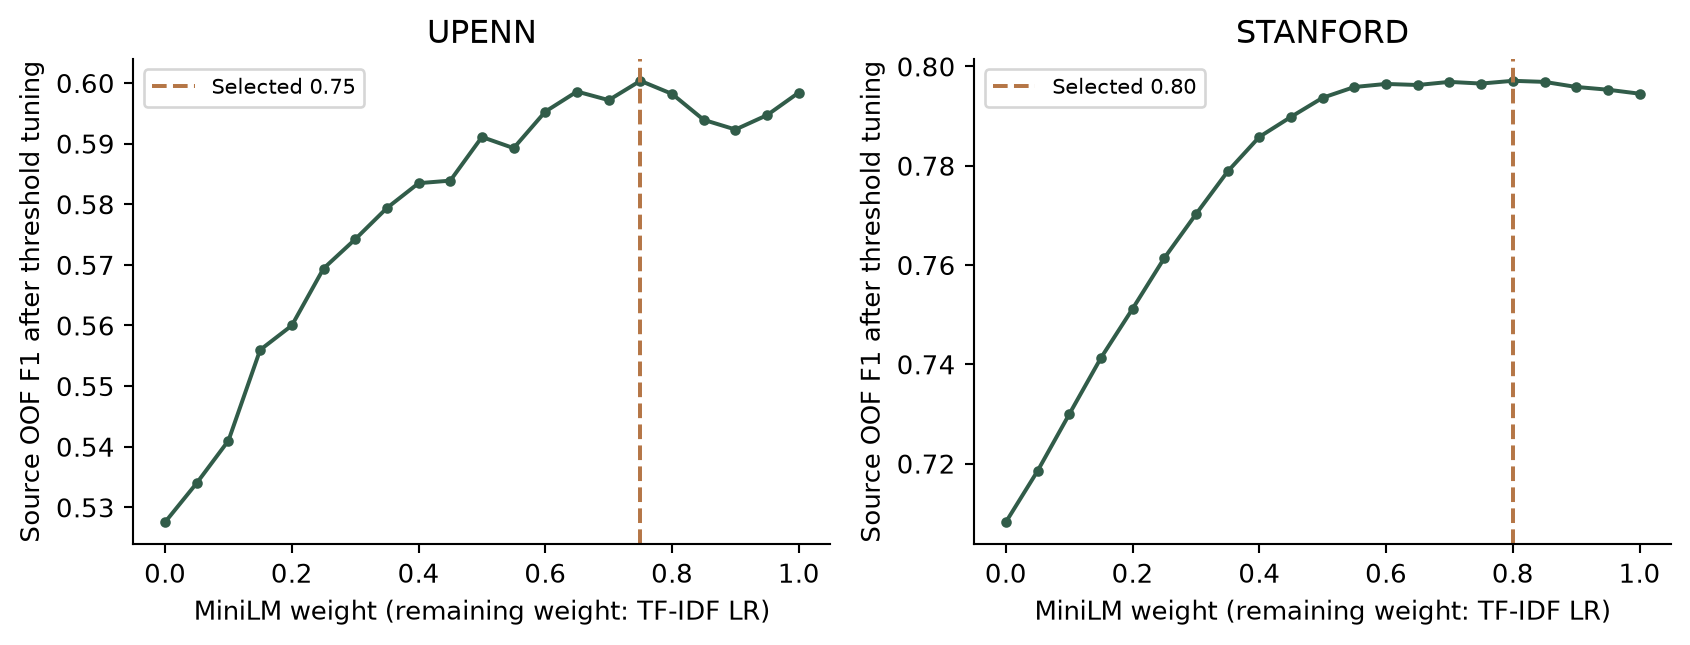

In [19]:
run_script('blend_trained_models.py')
run_script('package_blended_models.py')
blended=read_json('reports/ensembles/results.json')
for source in ['upenn','stanford']:
    print(source,read_json(f'reports/ensembles/{source}/decision_config.json'))
display(Image(filename=str(PROJECT/'reports/figures/blend_oof_search.png')))


## Tất cả số đo kiểm tra và so sánh

Precision/Recall/F1 tính cho lớp ưu tiên. Macro-F1 trung bình hai lớp; AP và ROC-AUC dùng điểm liên tục. P@20 và R@20 đánh giá hàng đợi 20 bài đầu. Không chọn cấu hình bằng các bảng test này.


In [20]:
fine=read_json('reports/fine_tuning/results.json')
all_results=baseline+fine+blended
keys=['precision','recall','f1','macro_f1','accuracy','average_precision','roc_auc','precision_at_20','recall_at_20']
for source,target in [('upenn','upenn'),('stanford','stanford'),('upenn','stanford'),('stanford','upenn')]:
    display(Markdown(f'### {source} → {target}'))
    selected=[r for r in all_results if r['train_source']==source and r['test_source']==target]
    show_table(['Method',*keys],[[r['model'],*[round(r[k],4) for k in keys]] for r in selected])
    for r in selected:
        print(r['model'],'confusion matrix [[TN, FP], [FN, TP]]:',r['confusion_matrix'])


### upenn → upenn

Method,precision,recall,f1,macro_f1,accuracy,average_precision,roc_auc,precision_at_20,recall_at_20
tfidf_logreg,0.5536,0.5082,0.5299,0.7432,0.9204,0.6596,0.9043,0.95,0.3115
tfidf_svm,0.5152,0.5574,0.5354,0.7442,0.9146,0.6558,0.9004,0.95,0.3115
tfidf_nb,0.337,0.5082,0.4052,0.6656,0.8683,0.4517,0.8422,0.75,0.2459
tfidf_dummy,0.0,0.0,0.0,0.4769,0.9117,0.0883,0.5,0.0,0.0
minilm_logreg,0.5,0.5902,0.5414,0.7463,0.9117,0.5776,0.9056,0.75,0.2459
finetuned_minilm,0.5676,0.6885,0.6222,0.7907,0.9262,0.7059,0.9119,0.9,0.2951
minilm_tfidf_blend,0.5915,0.6885,0.6364,0.799,0.9305,0.7224,0.9234,0.95,0.3115


tfidf_logreg confusion matrix [[TN, FP], [FN, TP]]: [[605, 25], [30, 31]]
tfidf_svm confusion matrix [[TN, FP], [FN, TP]]: [[598, 32], [27, 34]]
tfidf_nb confusion matrix [[TN, FP], [FN, TP]]: [[569, 61], [30, 31]]
tfidf_dummy confusion matrix [[TN, FP], [FN, TP]]: [[630, 0], [61, 0]]
minilm_logreg confusion matrix [[TN, FP], [FN, TP]]: [[594, 36], [25, 36]]
finetuned_minilm confusion matrix [[TN, FP], [FN, TP]]: [[598, 32], [19, 42]]
minilm_tfidf_blend confusion matrix [[TN, FP], [FN, TP]]: [[601, 29], [19, 42]]


### stanford → stanford

Method,precision,recall,f1,macro_f1,accuracy,average_precision,roc_auc,precision_at_20,recall_at_20
tfidf_logreg,0.6994,0.7412,0.7197,0.8257,0.8903,0.7817,0.9332,1.0,0.0181
tfidf_svm,0.676,0.7665,0.7184,0.8234,0.8858,0.78,0.9324,1.0,0.0181
tfidf_nb,0.5821,0.7186,0.6432,0.7735,0.8485,0.7155,0.8966,1.0,0.0181
tfidf_dummy,0.0,0.0,0.0,0.4475,0.8099,0.1901,0.5,0.1,0.0018
minilm_logreg,0.5422,0.7267,0.621,0.7563,0.8314,0.637,0.8897,0.75,0.0136
finetuned_minilm,0.7564,0.857,0.8036,0.8768,0.9204,0.8809,0.9639,1.0,0.0181
minilm_tfidf_blend,0.7643,0.8597,0.8092,0.8805,0.9229,0.8811,0.9637,1.0,0.0181


tfidf_logreg confusion matrix [[TN, FP], [FN, TP]]: [[4357, 352], [286, 819]]
tfidf_svm confusion matrix [[TN, FP], [FN, TP]]: [[4303, 406], [258, 847]]
tfidf_nb confusion matrix [[TN, FP], [FN, TP]]: [[4139, 570], [311, 794]]
tfidf_dummy confusion matrix [[TN, FP], [FN, TP]]: [[4709, 0], [1105, 0]]
minilm_logreg confusion matrix [[TN, FP], [FN, TP]]: [[4031, 678], [302, 803]]
finetuned_minilm confusion matrix [[TN, FP], [FN, TP]]: [[4404, 305], [158, 947]]
minilm_tfidf_blend confusion matrix [[TN, FP], [FN, TP]]: [[4416, 293], [155, 950]]


... (2 outputs left out)

tfidf_logreg confusion matrix [[TN, FP], [FN, TP]]: [[4517, 192], [768, 337]]
tfidf_svm confusion matrix [[TN, FP], [FN, TP]]: [[4485, 224], [728, 377]]
tfidf_nb confusion matrix [[TN, FP], [FN, TP]]: [[4170, 539], [702, 403]]
tfidf_dummy confusion matrix [[TN, FP], [FN, TP]]: [[4709, 0], [1105, 0]]
minilm_logreg confusion matrix [[TN, FP], [FN, TP]]: [[4428, 281], [757, 348]]
finetuned_minilm confusion matrix [[TN, FP], [FN, TP]]: [[4516, 193], [508, 597]]
minilm_tfidf_blend confusion matrix [[TN, FP], [FN, TP]]: [[4504, 205], [507, 598]]


### stanford → upenn

Method,precision,recall,f1,macro_f1,accuracy,average_precision,roc_auc,precision_at_20,recall_at_20
tfidf_logreg,0.2699,0.7213,0.3929,0.6377,0.8032,0.3803,0.8719,0.45,0.1475
tfidf_svm,0.2616,0.7377,0.3863,0.6309,0.7931,0.391,0.8712,0.55,0.1803
tfidf_nb,0.3826,0.7213,0.5,0.7135,0.8726,0.548,0.8869,0.7,0.2295
tfidf_dummy,0.0,0.0,0.0,0.4769,0.9117,0.0883,0.5,0.0,0.0
minilm_logreg,0.2593,0.8033,0.392,0.6289,0.78,0.3898,0.8606,0.35,0.1148
finetuned_minilm,0.2704,0.8689,0.4125,0.6391,0.7815,0.4873,0.9036,0.55,0.1803
minilm_tfidf_blend,0.2718,0.8689,0.4141,0.6404,0.7829,0.4639,0.9047,0.65,0.2131


tfidf_logreg confusion matrix [[TN, FP], [FN, TP]]: [[511, 119], [17, 44]]
tfidf_svm confusion matrix [[TN, FP], [FN, TP]]: [[503, 127], [16, 45]]
tfidf_nb confusion matrix [[TN, FP], [FN, TP]]: [[559, 71], [17, 44]]
tfidf_dummy confusion matrix [[TN, FP], [FN, TP]]: [[630, 0], [61, 0]]
minilm_logreg confusion matrix [[TN, FP], [FN, TP]]: [[490, 140], [12, 49]]
finetuned_minilm confusion matrix [[TN, FP], [FN, TP]]: [[487, 143], [8, 53]]
minilm_tfidf_blend confusion matrix [[TN, FP], [FN, TP]]: [[488, 142], [8, 53]]


## Biểu đồ từ dữ liệu thực nghiệm

Các hình được tạo từ JSON/CSV đã lưu: learning curves, 5-fold, so sánh P/R/F1, ma trận nhầm lẫn, Precision–Recall, chuyển nguồn và chọn ngưỡng. Không có số liệu mẫu thay cho kết quả training.


**ft_learning_curves.png**

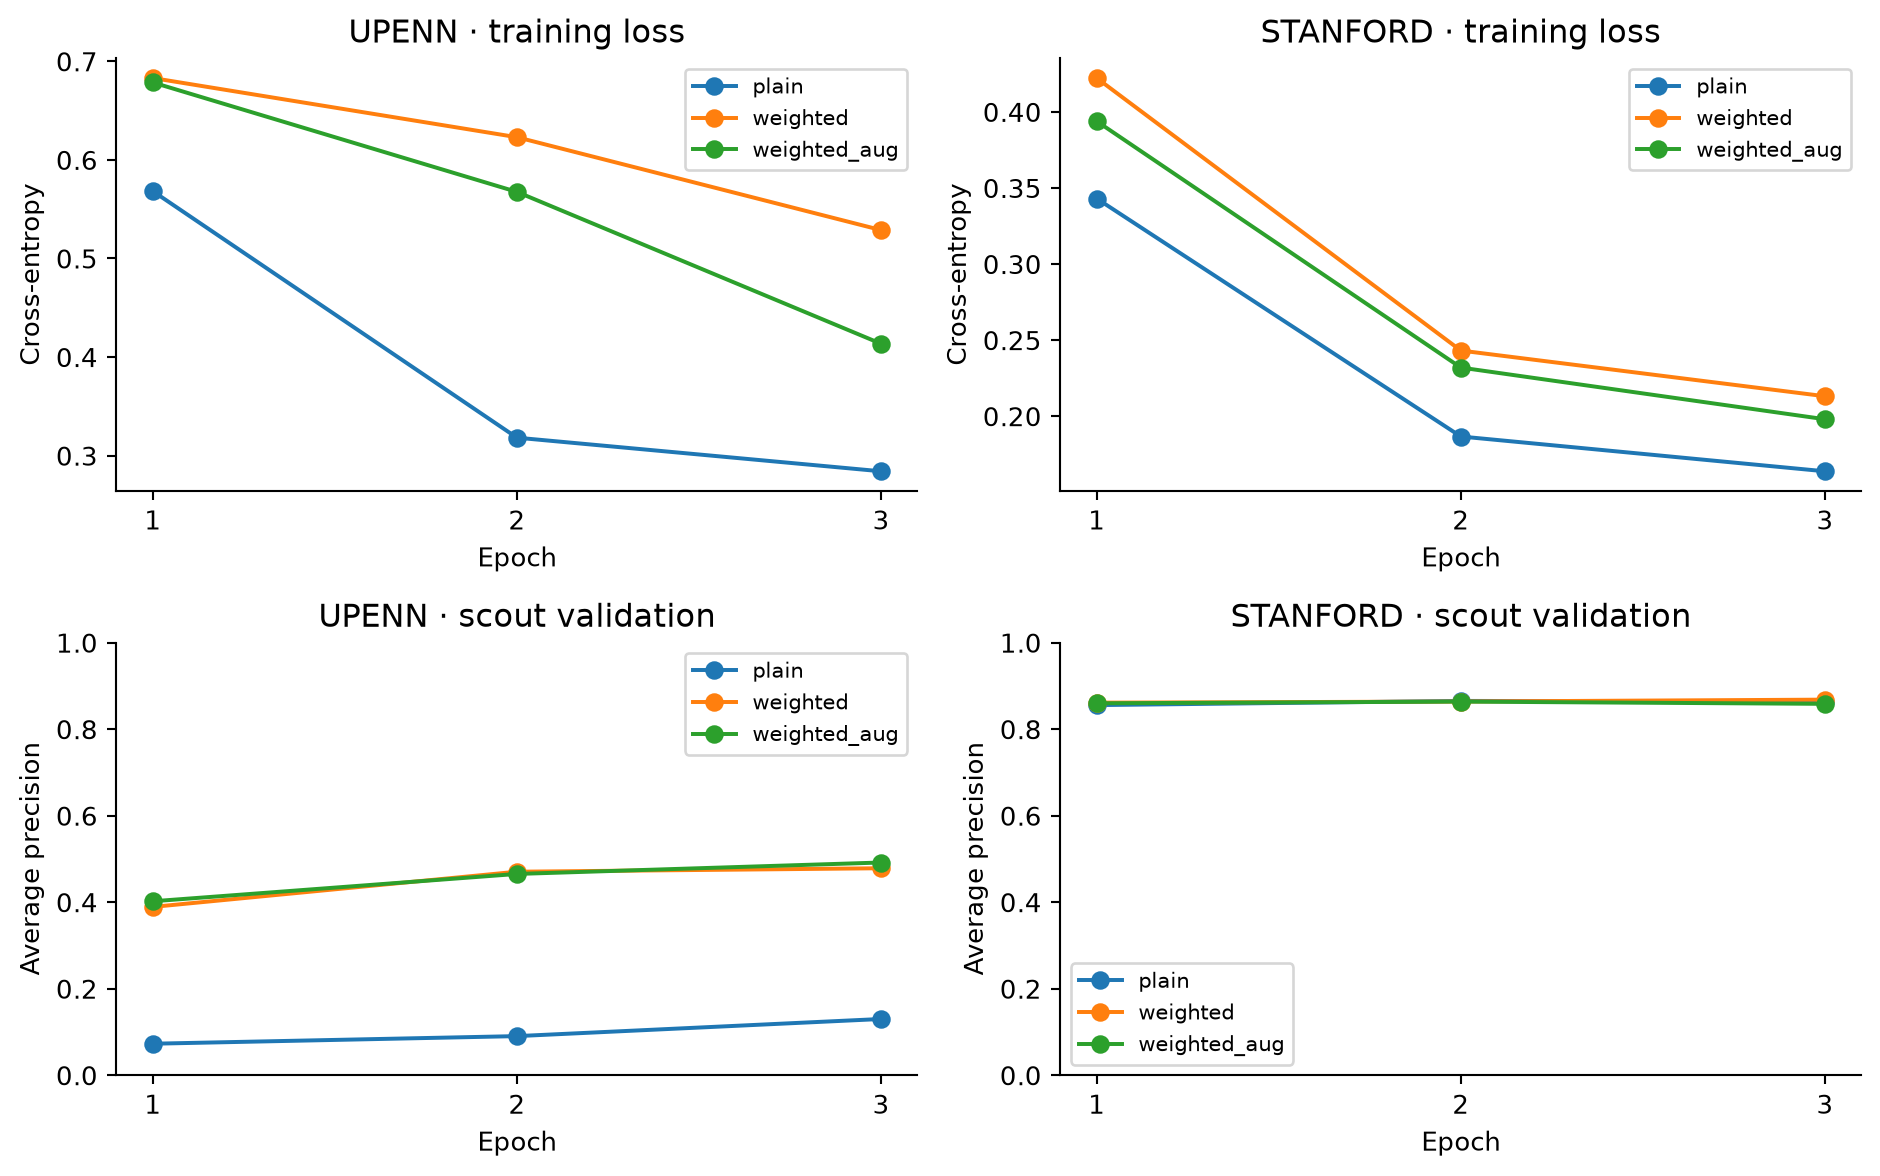

**ft_cv.png**

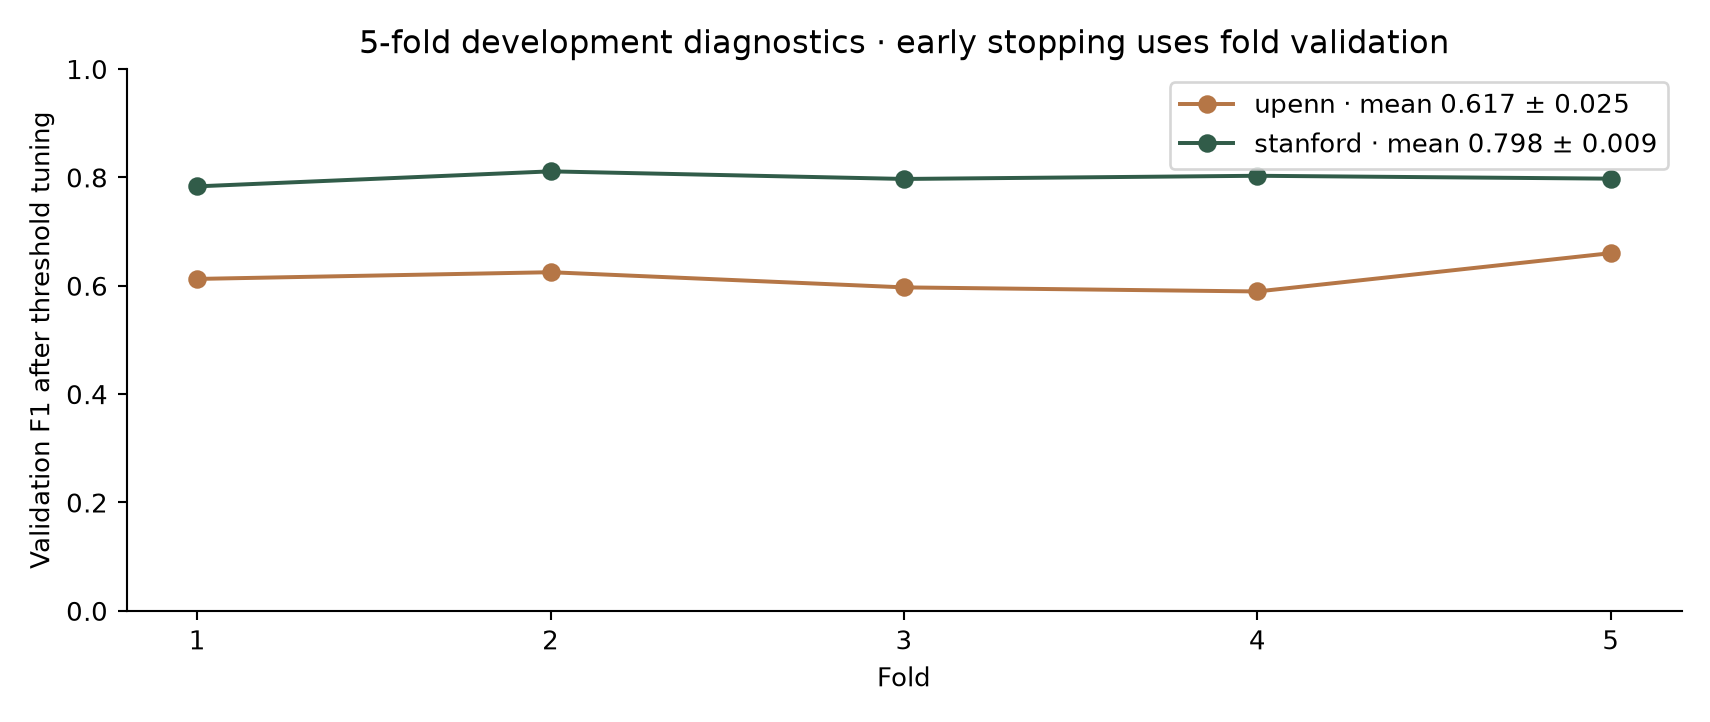

**ft_comparison.png**

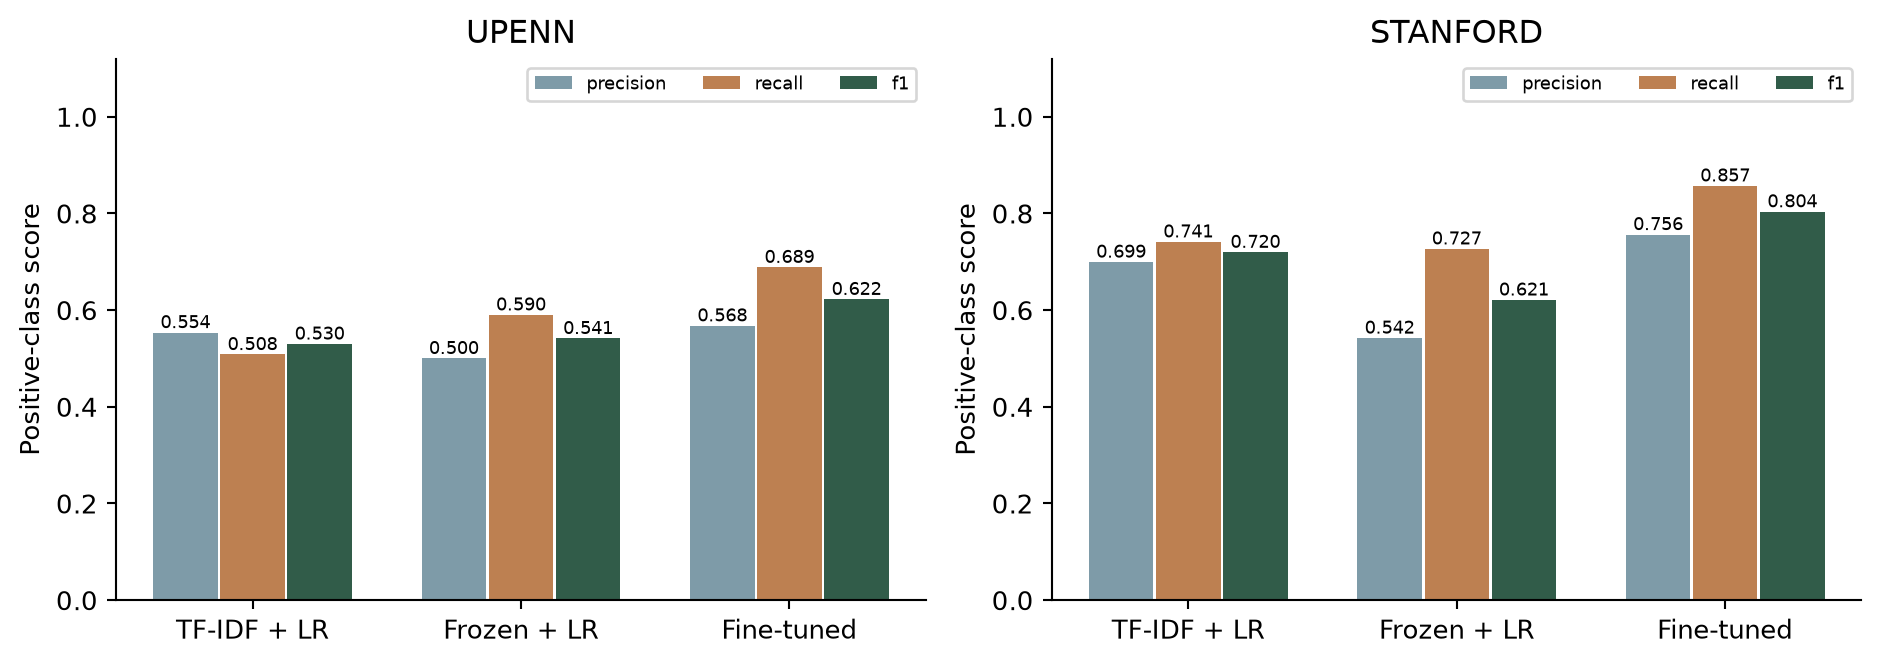

**ft_confusion.png**

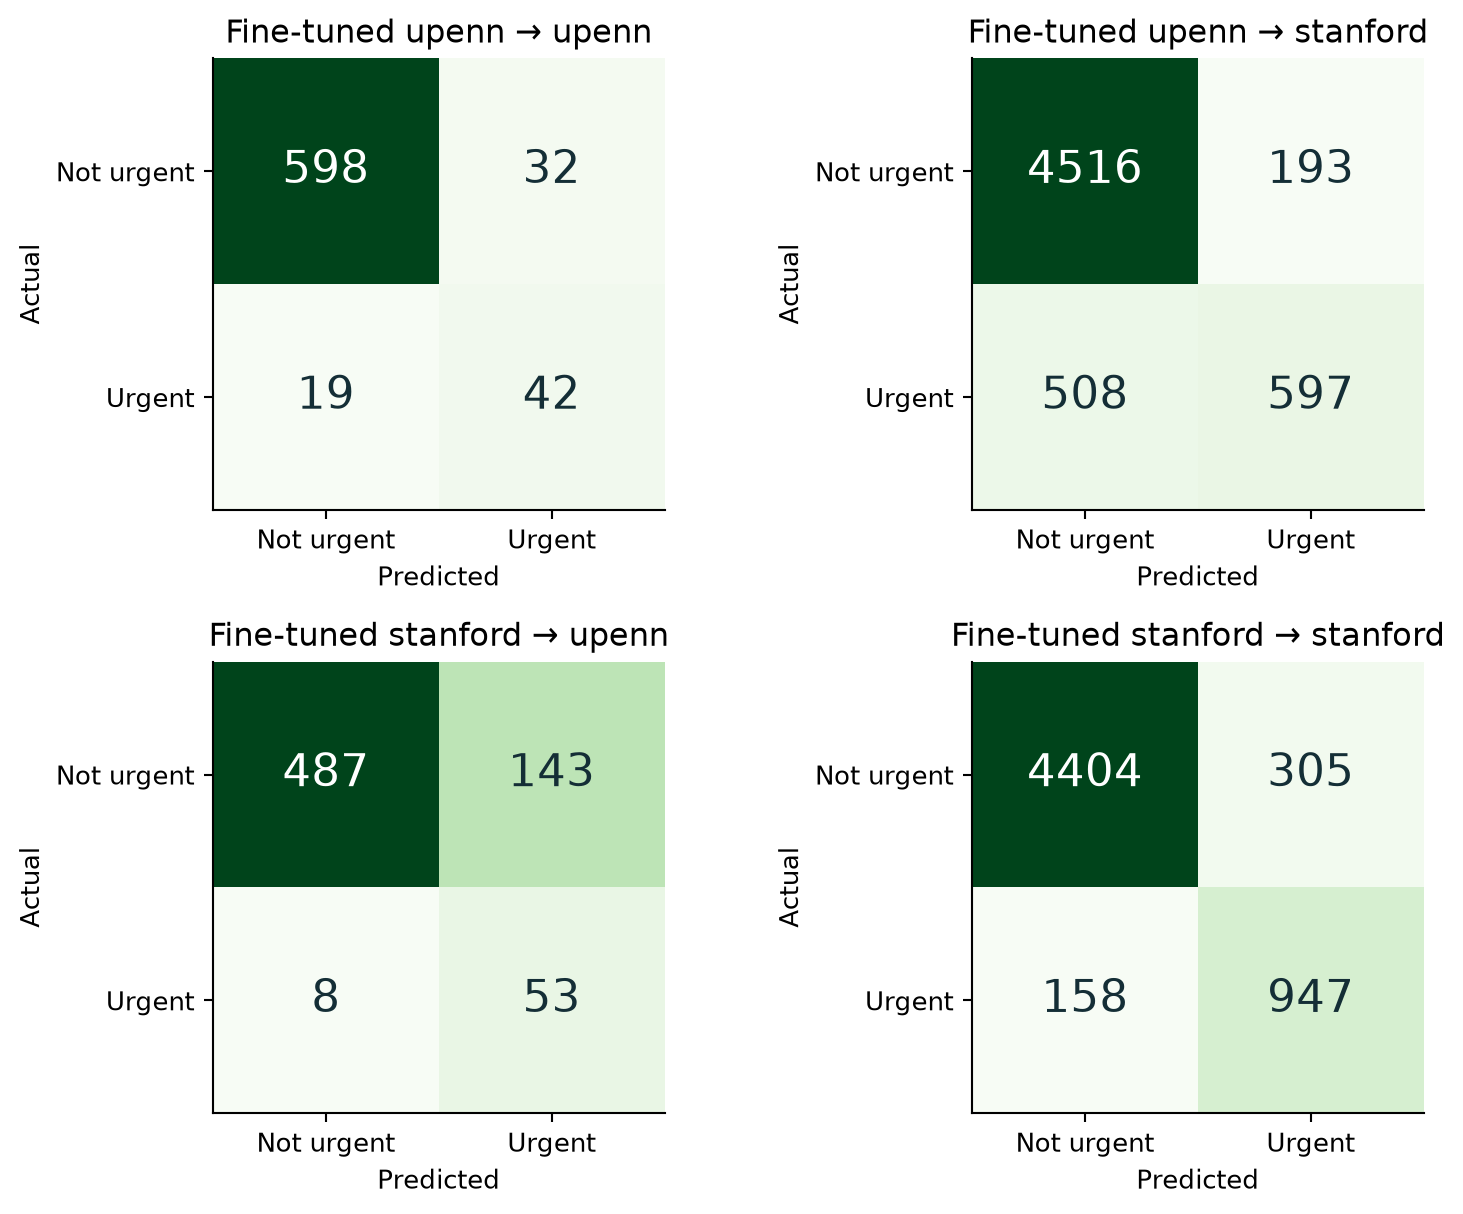

**ft_pr.png**

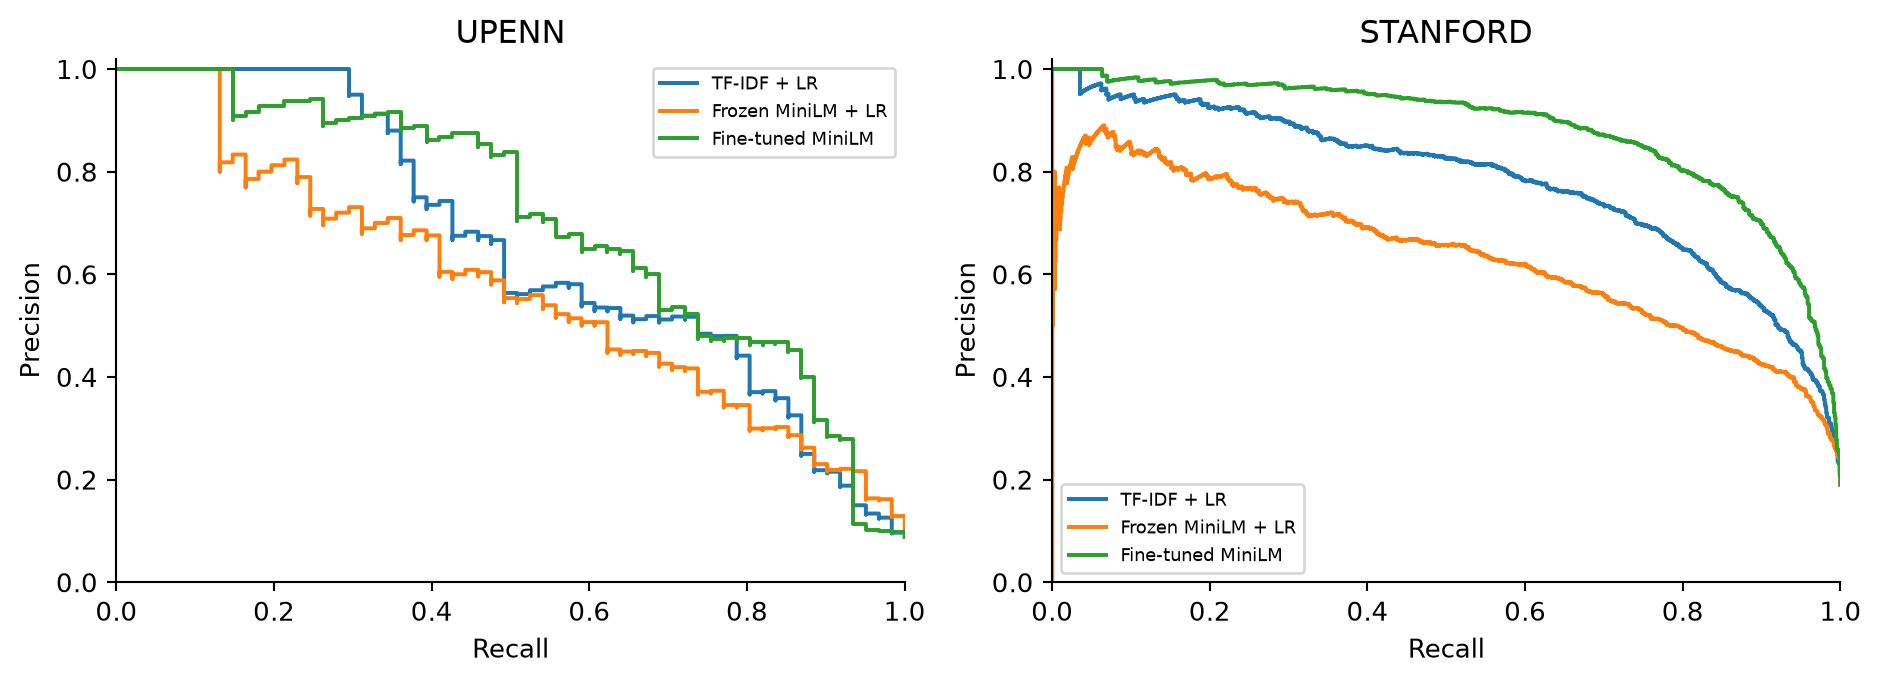

**upenn_metrics.png**

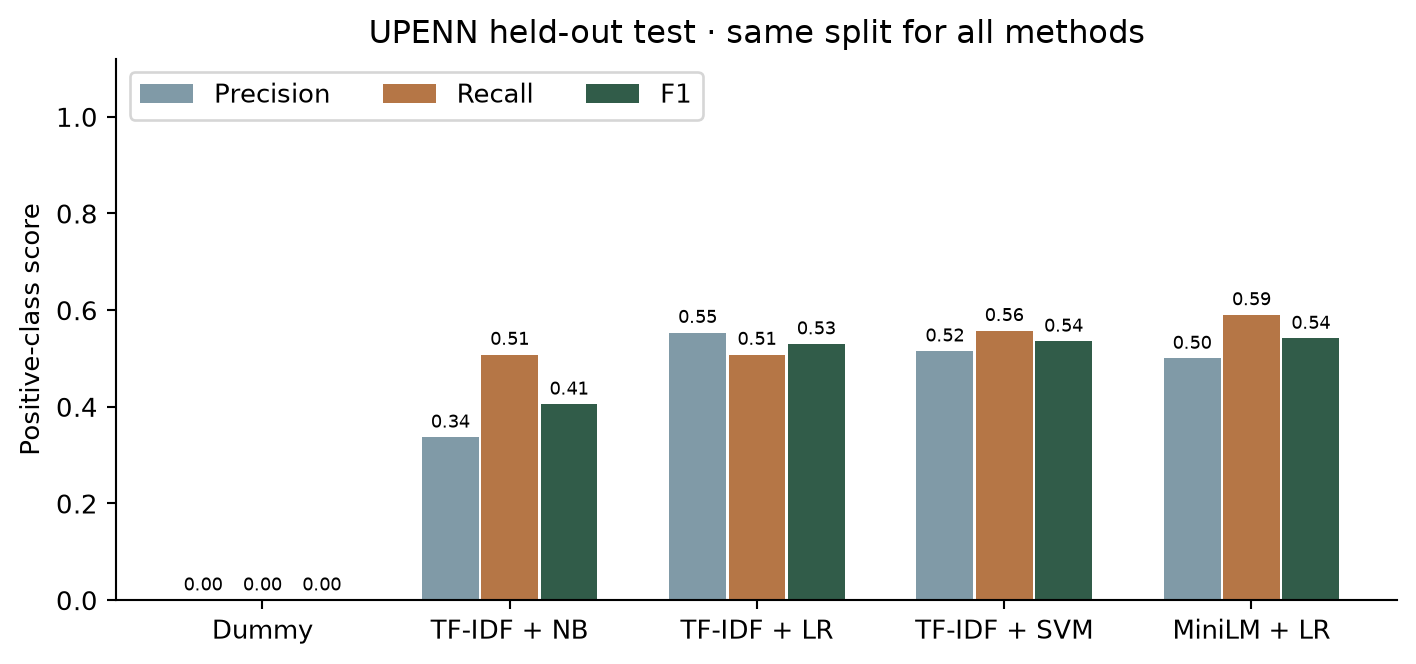

**stanford_metrics.png**

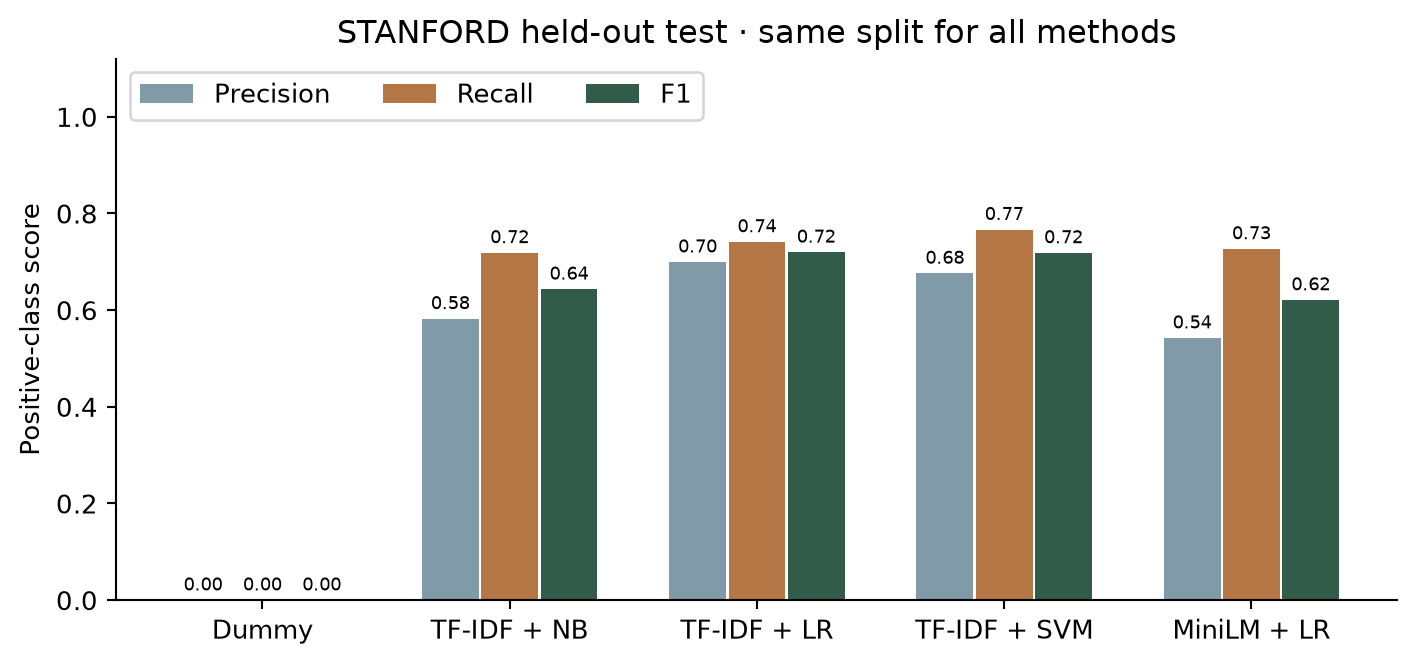

**transfer.png**

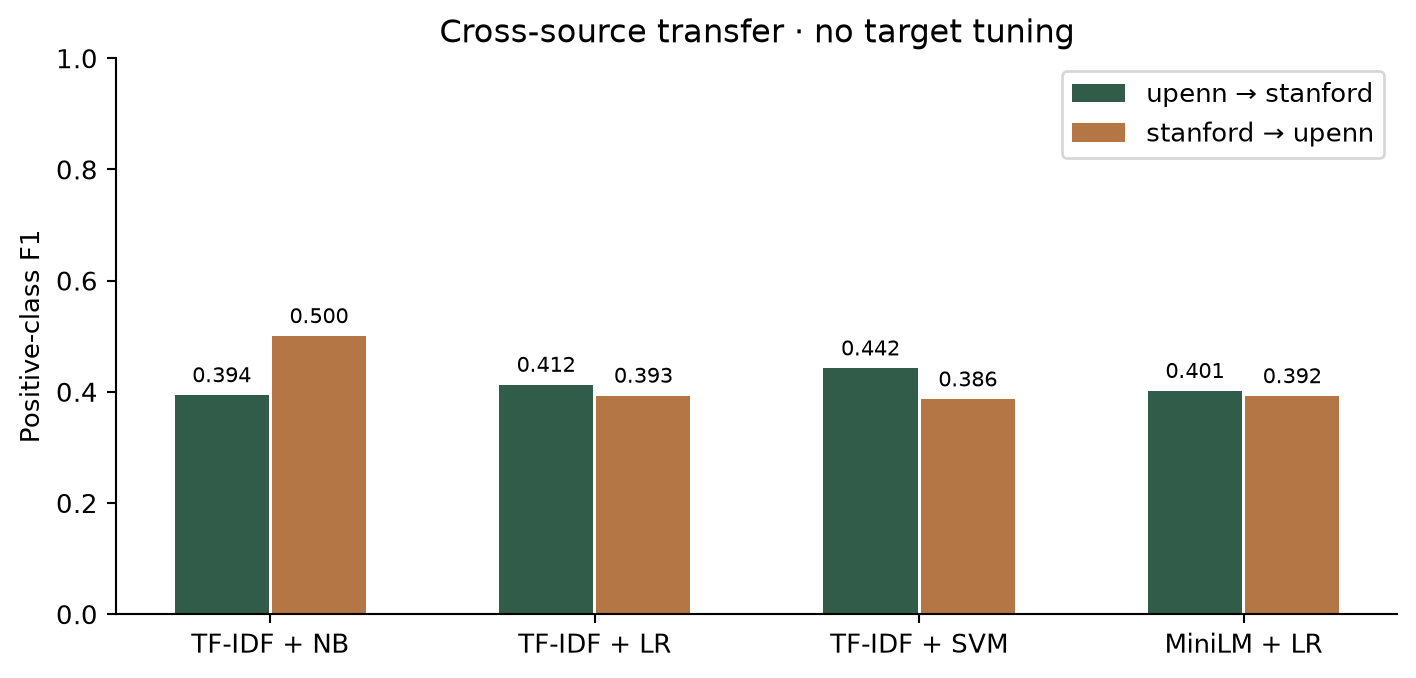

**confusion_four.png**

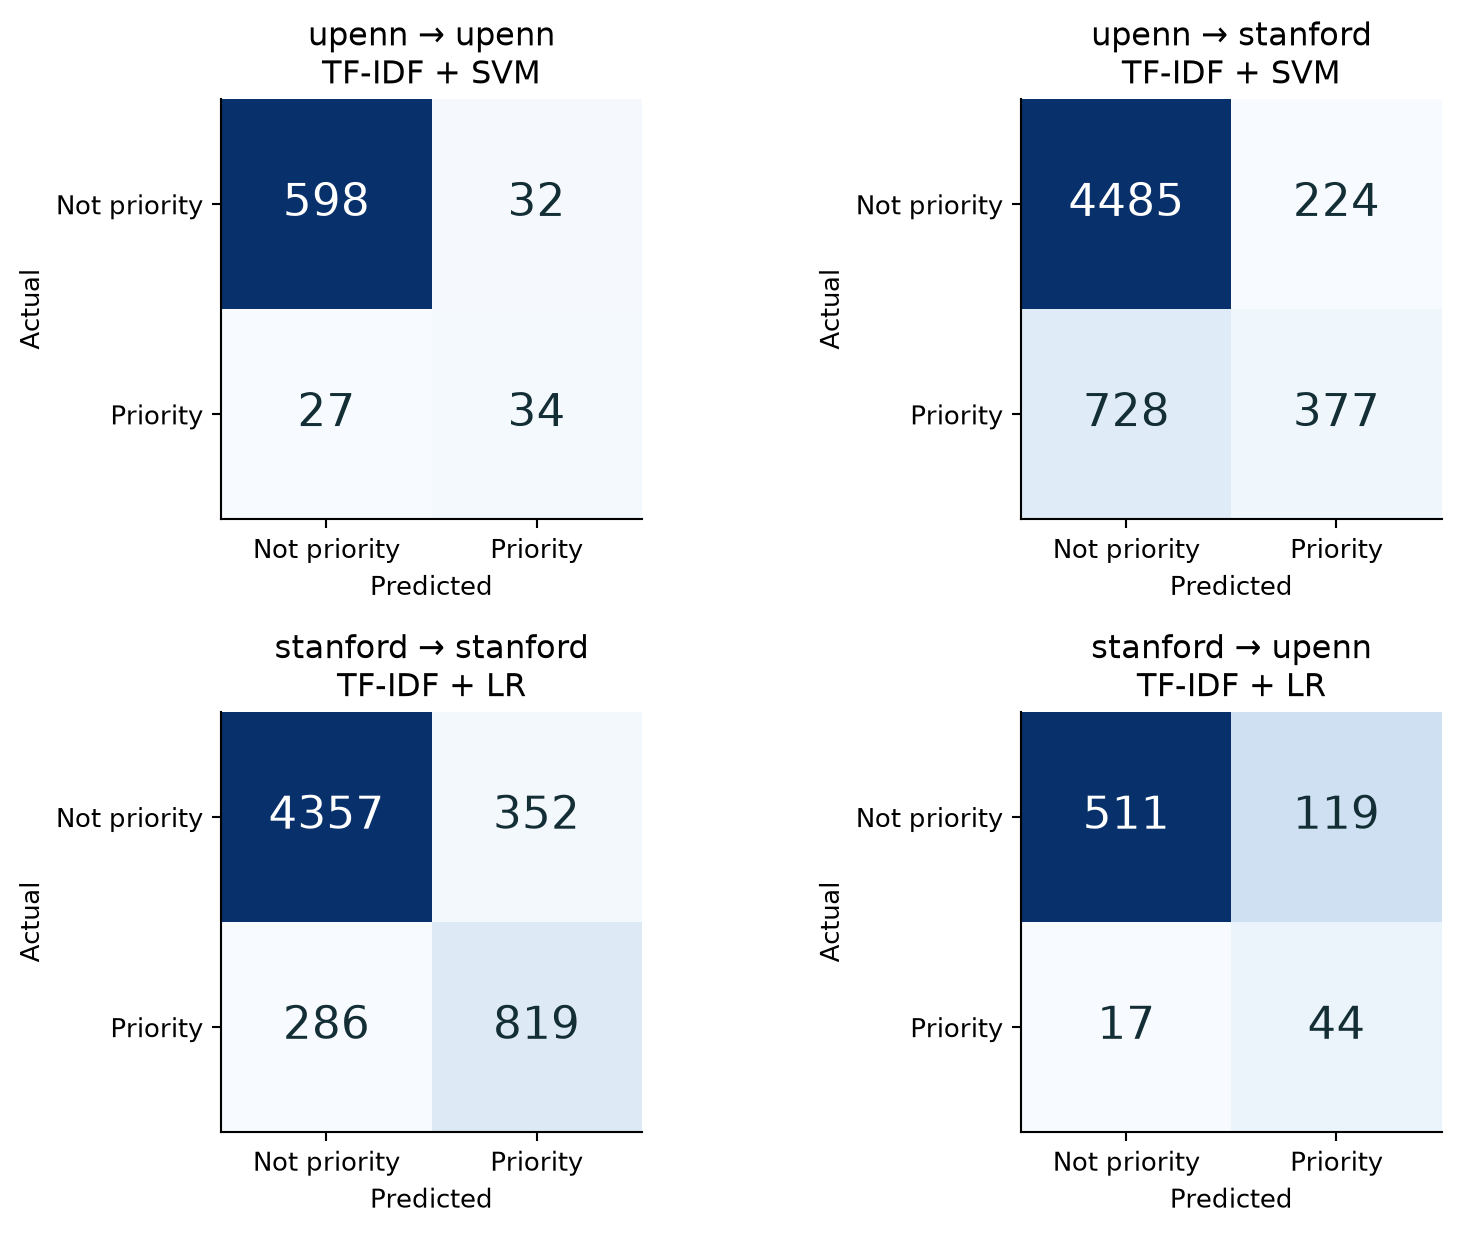

**upenn_pr.png**

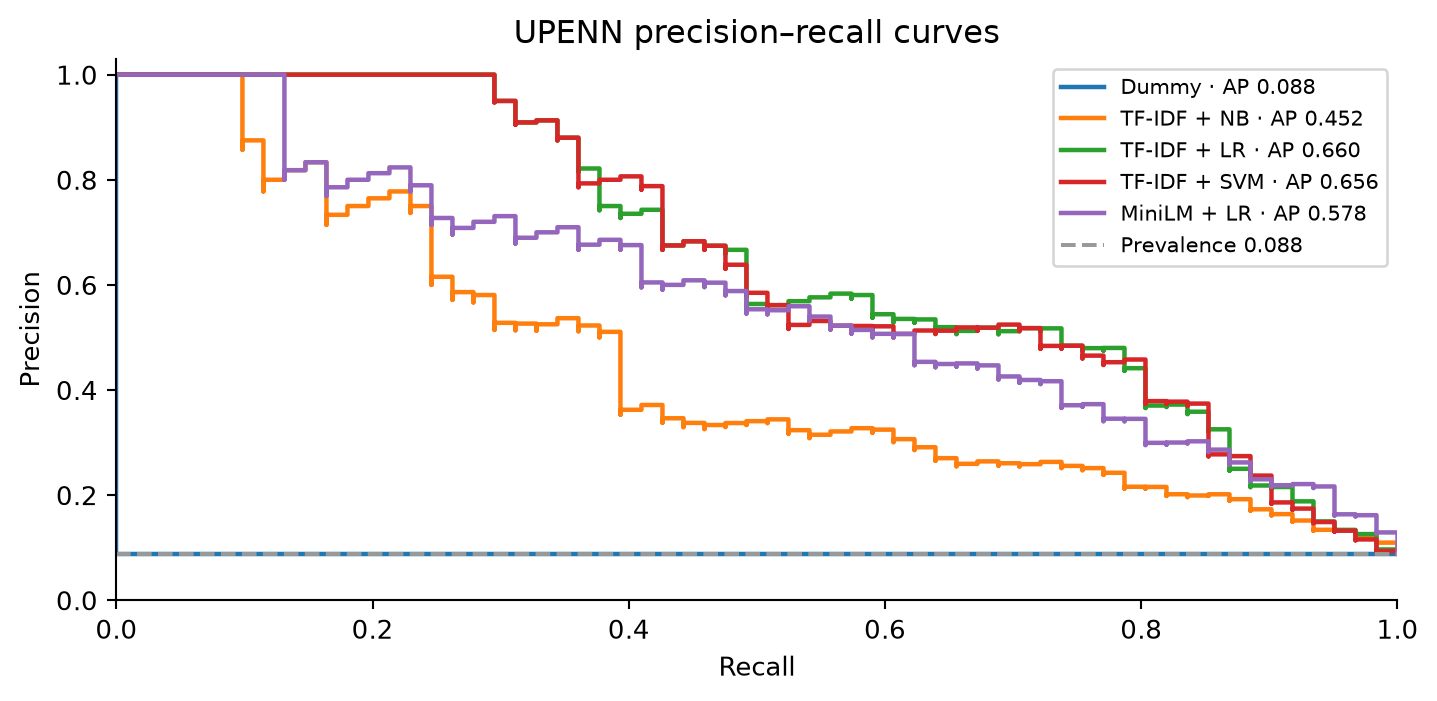

**stanford_pr.png**

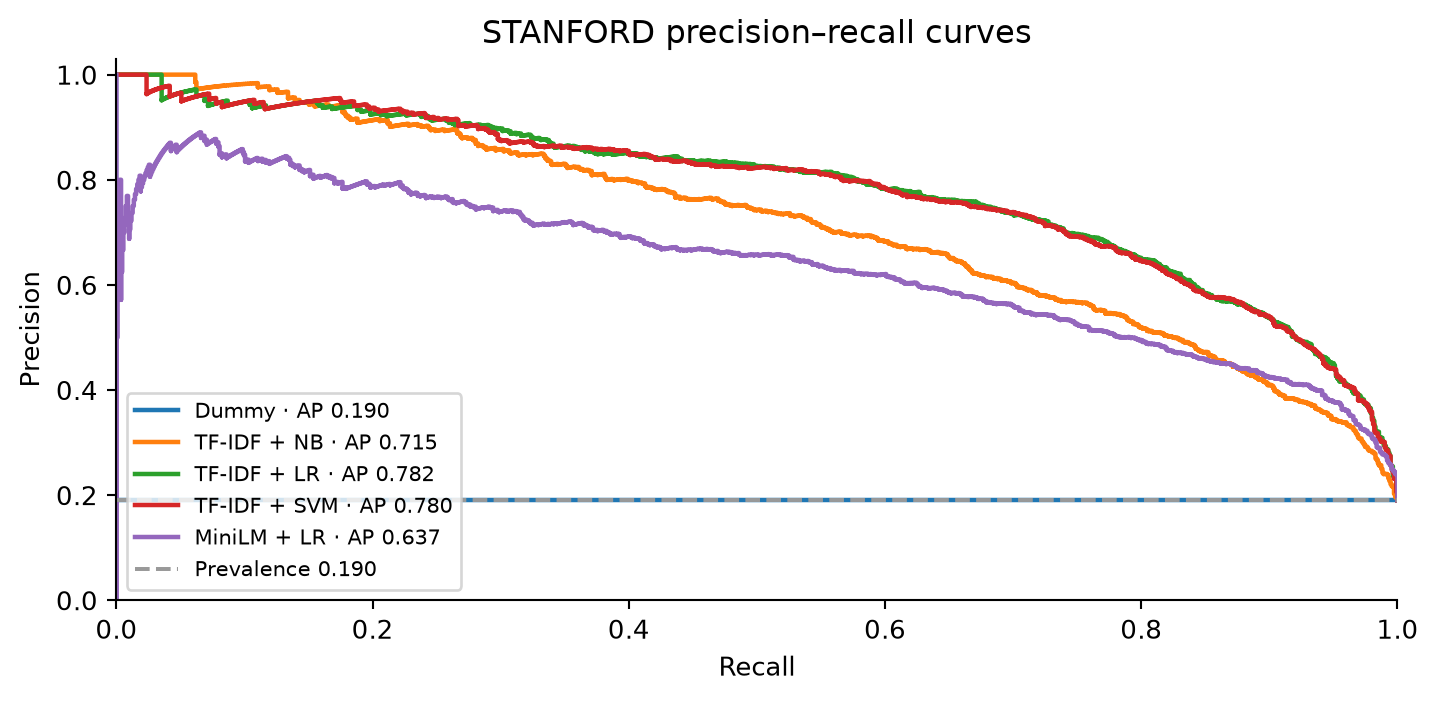

**threshold.png**

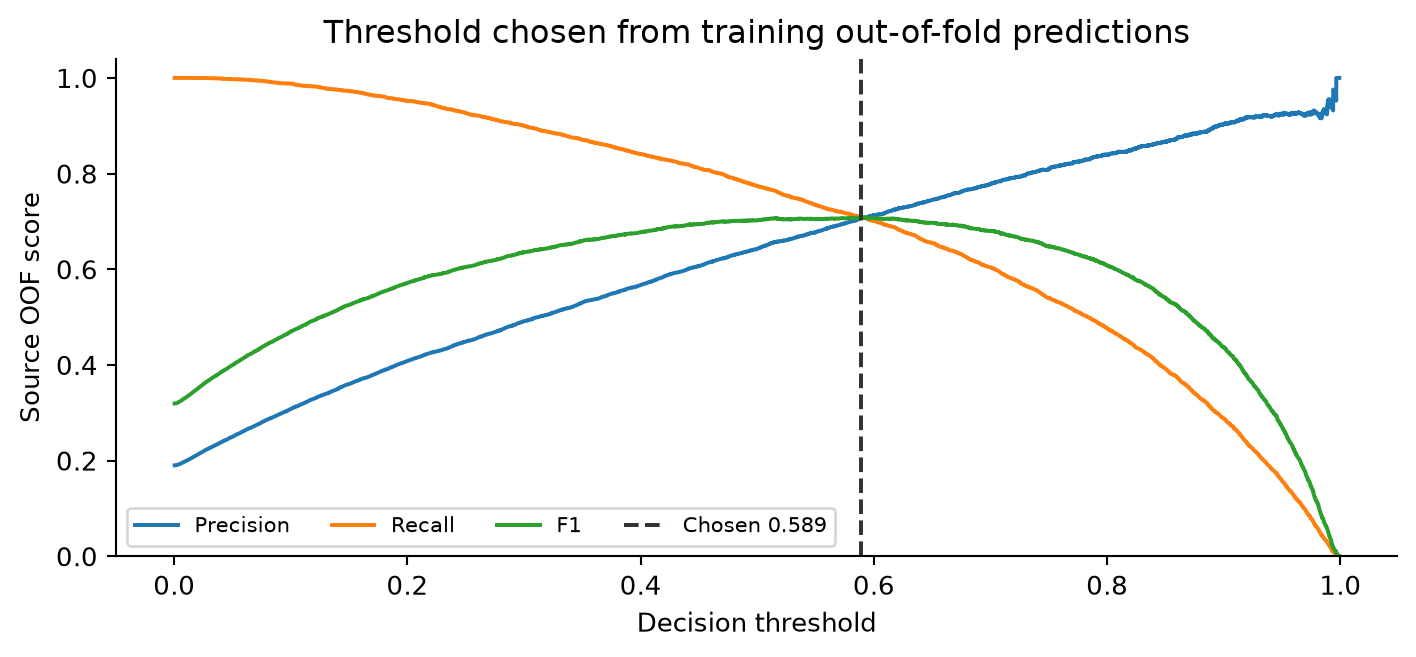

In [21]:
for name in ['ft_learning_curves.png','ft_cv.png','ft_comparison.png','ft_confusion.png','ft_pr.png',
             'upenn_metrics.png','stanford_metrics.png','transfer.png','confusion_four.png','upenn_pr.png','stanford_pr.png','threshold.png']:
    display(Markdown('**'+name+'**'))
    display(Image(filename=str(PROJECT/'reports/figures'/name)))


## Dự đoán sai và giới hạn

Ví dụ lấy từ test fine-tuned, không sửa nhãn để tăng điểm. Chênh lệch từ một seed chưa chứng minh ý nghĩa thống kê. MiniLM có thể cắt bài dài; nhãn urgency không đồng nhất với có câu hỏi. Chưa đánh giá tiếng Việt hoặc hiệu quả giảng viên thực tế.


In [22]:
import csv
for source in ['upenn','stanford']:
    with (PROJECT/f'reports/fine_tuning/{source}/predictions_{source}.csv').open() as handle:
        predictions=list(csv.DictReader(handle))
    wrong=[r for r in predictions if r['label']!=r['predicted']]
    display(Markdown(f'### {source}: {len(wrong)} wrong predictions'))
    show_table(['Post ID','True','Predicted','Score','Text excerpt'],
        [[r['post_id'],r['label'],r['predicted'],round(float(r['score']),4),r['text'][:240]] for r in wrong[:8]])


### upenn: 51 wrong predictions

Post ID,True,Predicted,Score,Text excerpt
upenn_000018,0,1,0.7353,"Is this when employees get actual stock in the company instead of options? Will there be a vesting period? If they get actual stock, do they have to pay for it at anytime or they get it at no cost?"
upenn_000062,0,1,0.8515,"The first page of the lecture slide shows a scenario that BOC loans $100,000 to an employee with annual interest rate 12%.So, the interest should be $12,000 after one year, for sure.However, since the employee paid the interest after three"
upenn_000188,0,1,0.8903,"Can someone explain this to me? If I complete the course without paying the $49 will I not get a certificate of completion? If you have to buy this to get a signature does it carry over to different courses as well, or do you have to buy on"
upenn_000237,0,1,0.821,"i am working on a ratios of a company in theÂ construction industry.the company has very low inventory level (2%, 1% Â & 2% in 2011, 2012 & 2013Â respectively) but high volume of ""Costs and estimated earnings, net in excess of billings onÂ"
upenn_000288,0,1,0.8684,"I hope that I am wring in the right forum.In the video 'Financial Statement an Closing Entries', around playing time 12:21, professor mentioned 'Debit Retained Earning'. But I guess what he actually meant was 'Debit Rental Revenue'.Probably"
upenn_000303,1,0,0.5649,"Thank you [REDACTED] for your quick reply and explanation. Two questions though :1- What is the difference between Inventory(materials) and Supplies? I would consider oranges, water, sugar as supplies . Never knew about Inventory(materials)"
upenn_000362,1,0,0.4595,"My concern was twofold. Â 1) When does the addition (of the two cash amounts) take place? Â There could be the possibility of error in adding the amounts. Â (Granted this is a fairly simple transaction. Â But, in a more complex transaction"
upenn_000435,0,1,0.7334,"Is this a substantially different question than the one asked in Q. 4? In other words, are we not solving the same integral that we did in Q. 4, but setting the answer to $$\frac{1}{4}$$ and $$\frac{3}{4}$$ respectively?Edit: Never mind, I"


### stanford: 463 wrong predictions

Post ID,True,Predicted,Score,Text excerpt
stanford_000035,1,0,0.3394,"I am teaching the inclusive sections of alg 2 for the first time this year. A little nervous, but very exciting. Any suggestions?"
stanford_000168,0,1,0.9785,how do i take the survey?
stanford_000256,0,1,0.6968,"I had some trouble reading this as well. I THINK it works like this: each session has some tasks (problems), on the progress panel it shows the session and the score on each problem. These are in the order they happen in the session. I had"
stanford_000414,0,1,0.784,It might be helpful to do a numbertalk with 7 x 8. How many ways could you do it?
stanford_001338,1,0,0.216,"I don't see clear learning goals for this task. Are we hoping the students will describe the growth mathematically? Come up with the quadratic function? And what kind of specific, critical feedback would you give to students' work on this t"
stanford_001693,0,1,0.8019,I posted comments on the video and there not online ?
stanford_002004,0,1,0.513,"Hi,As I was assessing peer responses to the activity of designing an open task, I was reading one person's response and he mentioned that he used a challenge posted on Dan Meyer's site about reforming a closed task about graphing the pric"
stanford_002129,1,0,0.0258,"Jo, First of all I'd like to thank for putting a wealth of information and the course online.I am wondering we keep hearing US kids are at the bottom of the pile for math. What have or can we learn from other countries at the top? Singap"


## Dùng thư mục model để dự đoán câu mới

Đổi `TEXT_TO_PREDICT` rồi chạy lại cell. Model và tokenizer được đọc từ thư mục local; không cần gọi AI API. Score được so với ngưỡng lưu trong decision_config.json.


In [23]:
TEXT_TO_PREDICT = 'I cannot submit my assignment and the deadline is tonight. Please help!'
MODEL_SOURCE = 'stanford'
run_script('predict_urgency.py', '--model',PROJECT/f'models/urgency_minilm_{MODEL_SOURCE}', '--text',TEXT_TO_PREDICT)
print(read_json(f'reports/fine_tuning/{MODEL_SOURCE}/export_check.json'))
run_script('standalone_blend.py','--model',PROJECT/f'models/urgency_hybrid_{MODEL_SOURCE}','--text',TEXT_TO_PREDICT)


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "score": 0.9745758175849915,
  "threshold": 0.34997692704200745,
  "urgent": true,
  "label": "URGENT"
}


{'examples': [{'predicted': 1, 'score': 0.9744347929954529, 'text': 'I cannot submit my assignment and the deadline is tonight. Please help!'}, {'predicted': 0, 'score': 0.005469274707138538, 'text': 'Thank you for the helpful explanation.'}], 'max_score_difference': 0.0, 'passed': True}


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "score": 0.9736286113963777,
  "threshold": 0.3931987027552757,
  "urgent": true,
  "label": "URGENT",
  "minilm_score": 0.9745758175849915,
  "tfidf_score": 0.9698397866419225
}


## Tải model và bằng chứng

File ZIP chứa model fine-tuned, model hybrid độc lập, cấu hình, tokenizer, metrics, fold IDs và hình. Các CSV raw vẫn có URL và hash trong audit; không đưa raw vào ZIP model.


In [24]:
from zipfile import ZipFile, ZIP_DEFLATED
archive=PROJECT/'urgency_minilm_and_statistics.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for folder in [PROJECT/'models/urgency_minilm_upenn',PROJECT/'models/urgency_minilm_stanford',
                   PROJECT/'models/urgency_hybrid_upenn',PROJECT/'models/urgency_hybrid_stanford',
                   PROJECT/'reports/fine_tuning',PROJECT/'reports/ensembles',PROJECT/'reports/figures',PROJECT/'reports/experiments']:
        for file in folder.rglob('*'):
            if file.is_file():
                z.write(file,str(file.relative_to(PROJECT)))
    for source in ['upenn','stanford']:
        file=PROJECT/f'models/{source}__tfidf_logreg.joblib'
        z.write(file,str(file.relative_to(PROJECT)))
print('Download from Kaggle Output:',archive,'MB:',round(archive.stat().st_size/1024**2,1))


Download from Kaggle Output: /Users/nhaterik/lastyear/machine/Project/urgency_minilm_and_statistics.zip MB: 342.5


## Nguồn

- Švábenský và cộng sự, *Towards Generalizable Detection of Urgency of Discussion Forum Posts*: https://arxiv.org/abs/2307.07614
- Dữ liệu và mã bổ trợ: https://github.com/pcla-code/forum-posts-urgency
- Agrawal và Paepcke, *The Stanford MOOC Posts Dataset*, dẫn trong README kho trên.
- MiniLM: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
- Transformers text classification: https://huggingface.co/docs/transformers/tasks/sequence_classification
